# Proyek Machine Learning Membuat Model Sistem Rekomendasi Anime
- **Nama:** Septi Isdayanna
- **Email:** septiisdaynnaa@gmail.com
- **ID Dicoding:** septi_isdayanna

# Import Library

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import math
from scipy.sparse import hstack
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Dot, Add, Flatten, Concatenate, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.initializers import RandomNormal
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

**INSIGHT**

---

**Library Umum dan Pra-pemrosesan Data:**

* **`google.colab.files`**: Untuk unggah/unduh file di Google Colab.
* **`pandas` (`pd`)**: Krusial untuk manipulasi, pembersihan, dan analisis data anime.
* **`numpy` (`np`)**: Fondasi komputasi numerik, esensial untuk operasi array/matriks dalam model.
* **`matplotlib.pyplot` (`plt`)** & **`seaborn` (`sns`)**: Untuk visualisasi data guna memahami distribusi dan pola.
* **`pickle`**: Menyimpan dan memuat objek Python (model terlatih, data terproses) untuk efisiensi.
* **`math`**: Menyediakan fungsi matematika dasar.
* **`scipy.sparse.hstack`**: Menggabungkan matriks sparse, berguna untuk kombinasi fitur CBF.


**Library untuk Content-Based Filtering (CBF):**

*Merekomenendasikan item berdasarkan kemiripan atributnya.*

* **`sklearn.preprocessing.MinMaxScaler`**: Menskalakan fitur numerik (skor, episode) ke rentang standar.
* **`sklearn.feature_extraction.text.TfidfVectorizer`**: **Kunci CBF berbasis teks**. Mengubah teks (deskripsi, genre) menjadi vektor numerik TF-IDF yang merepresentasikan pentingnya kata.
* **`sklearn.metrics.pairwise.cosine_similarity`**: Menghitung kemiripan antar anime berdasarkan representasi vektor kontennya.

**Library untuk Collaborative Filtering (CF):**

*Merekomenendasikan item berdasarkan pola perilaku pengguna serupa, di sini dengan pendekatan neural network.*

* **`sklearn.metrics.mean_squared_error`, `mean_absolute_error`**: Metrik untuk evaluasi akurasi prediksi rating model.
* **`tensorflow` (`tf`)** & **`tensorflow.keras`**: **Inti implementasi model CF berbasis neural network.**
    * **`keras.layers` (`Input`, `Embedding`, `Dot`, `Add`, `Flatten`, `Concatenate`, `Dense`, `Dropout`)**: Komponen pembangun arsitektur neural network.
        * **`Embedding`**: Sangat penting untuk CF; mempelajari representasi vektor laten (embedding) untuk pengguna dan anime, menangkap preferensi dan karakteristik secara implisit.
        * Lainnya (`Dot`, `Add`, `Dense`, dll.): Untuk mengkombinasikan embedding dan membangun layer model.
    * **`keras.models.Model`**: Mendefinisikan model Keras.
    * **`keras.optimizers.Adam`**: Algoritma optimasi untuk melatih neural network.
    * **`keras.regularizers.l2`**: Teknik regularisasi L2 untuk mencegah overfitting.
    * **`keras.initializers.RandomNormal`**: Menginisialisasi bobot layer.
    * **`keras.callbacks` (`EarlyStopping`, `ModelCheckpoint`, `ReduceLROnPlateau`)**: Callback untuk mengontrol proses training (mencegah overfitting, menyimpan model terbaik, menyesuaikan learning rate).
* **`sklearn.model_selection.train_test_split`**: Membagi dataset menjadi set training dan testing/validasi untuk evaluasi generalisasi model.

# Data Loading

In [ ]:
# Upload kaggle.json
files.upload()

In [7]:
# Setup kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download dan extract dataset
!kaggle datasets download -d CooperUnion/anime-recommendations-database
!unzip -q anime-recommendations-database.zip

Dataset URL: https://www.kaggle.com/datasets/CooperUnion/anime-recommendations-database
License(s): CC0-1.0
  0% 0.00/25.0M [00:00<?, ?B/s]
100% 25.0M/25.0M [00:00<00:00, 698MB/s]


**INSIGHT**

---

* **Unggah Kredensial Kaggle**:
`files.upload()`: Meminta unggahan file `kaggle.json` (kunci API Kaggle).

* **Konfigurasi Kaggle API**:
`!mkdir ...`, `!cp ...`, `!chmod ...`: Membuat folder `.kaggle`, menyalin `kaggle.json` ke sana, dan mengatur izin file agar API Kaggle bisa digunakan.

* **Unduh & Ekstrak Dataset**:
`!kaggle datasets download ...`: Mengunduh dataset "Anime Recommendations Database" dari Kaggle.
`!unzip ...`: Mengekstrak file ZIP dataset yang telah diunduh.

* **Hasilnya**: File dataset (`anime.csv` dan `rating.csv`) sekarang tersedia di lingkungan Colab untuk diolah.

# Data Understanding

## Anime

In [2]:
# Baca file CSV untuk 'anime'
anime = pd.read_csv('/content/anime.csv')
anime.head()

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266


In [ ]:
# Menampilkan informasi tentang dataset, termasuk jumlah baris, kolom, dan tipe data
anime.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  object 
 2   genre     12232 non-null  object 
 3   type      12269 non-null  object 
 4   episodes  12294 non-null  object 
 5   rating    12064 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 672.5+ KB


In [ ]:
# Menampilkan statistik deskriptif dari dataset untuk fitur numerik
anime.describe()

,anime_id,rating,members
count,12294.000000,12064.000000,1.229400e+04
mean,14058.221653,6.473902,1.807134e+04
std,11455.294701,1.026746,5.482068e+04
min,1.000000,1.670000,5.000000e+00
25%,3484.250000,5.880000,2.250000e+02
50%,10260.500000,6.570000,1.550000e+03
75%,24794.500000,7.180000,9.437000e+03
max,34527.000000,10.000000,1.013917e+06


In [ ]:
# Menampilkan statistik deskriptif untuk kolom 'episodes'
anime[anime['episodes'] != 'Unknown']['episodes'].astype(int).describe()

,episodes
count,11954.000000
mean,12.382550
std,46.865352
min,1.000000
25%,1.000000
50%,2.000000
75%,12.000000
max,1818.000000


In [ ]:
# Menampilkan informasi jumlah nilai unique tiap kolom kategorikal
for col in anime.select_dtypes(include='object').columns:
  print(f"Nama Kolom: {col}")
  print(f"Jumlah Data: {len(anime[col].unique())}")
  print(anime[col].unique())
  print("\n")

Nama Kolom: name
Jumlah Data: 12292
['Kimi no Na wa.' 'Fullmetal Alchemist: Brotherhood' 'Gintama°' ...
 'Violence Gekiga David no Hoshi'
 'Violence Gekiga Shin David no Hoshi: Inma Densetsu'
 'Yasuji no Pornorama: Yacchimae!!']


Nama Kolom: genre
Jumlah Data: 3265
['Drama, Romance, School, Supernatural'
 'Action, Adventure, Drama, Fantasy, Magic, Military, Shounen'
 'Action, Comedy, Historical, Parody, Samurai, Sci-Fi, Shounen' ...
 'Hentai, Sports' 'Drama, Romance, School, Yuri' 'Hentai, Slice of Life']


Nama Kolom: type
Jumlah Data: 7
['Movie' 'TV' 'OVA' 'Special' 'Music' 'ONA' nan]


Nama Kolom: episodes
Jumlah Data: 187
['1' '64' '51' '24' '10' '148' '110' '13' '201' '25' '22' '75' '4' '26'
 '12' '27' '43' '74' '37' '2' '11' '99' 'Unknown' '39' '101' '47' '50'
 '62' '33' '112' '23' '3' '94' '6' '8' '14' '7' '40' '15' '203' '77' '291'
 '120' '102' '96' '38' '79' '175' '103' '70' '153' '45' '5' '21' '63' '52'
 '28' '145' '36' '69' '60' '178' '114' '35' '61' '34' '109' '20' '9' '49

In [ ]:
# Split kolom 'genre' ke individual genre
genre_series = anime['genre'].str.split(', ', expand=True).stack().value_counts()

# Hitung genre unique
print(f"Jumlah Data: {len(genre_series)}")

# Hitung jumlah anime per genre
print("Jumlah Anime tiap Genre:")
print(genre_series.head(50)) # Tampilkan 50 genre teratas

Jumlah Data: 43
Jumlah Anime tiap Genre:
Comedy           4645
Action           2845
Adventure        2348
Fantasy          2309
Sci-Fi           2070
Drama            2016
Shounen          1712
Kids             1609
Romance          1464
School           1220
Slice of Life    1220
Hentai           1141
Supernatural     1037
Mecha             944
Music             860
Historical        806
Magic             778
Ecchi             637
Shoujo            603
Seinen            547
Sports            543
Mystery           495
Super Power       465
Military          426
Parody            408
Space             381
Horror            369
Harem             317
Demons            294
Martial Arts      265
Dementia          240
Psychological     229
Police            197
Game              181
Samurai           148
Vampire           102
Thriller           87
Cars               72
Shounen Ai         65
Shoujo Ai          55
Josei              54
Yuri               42
Yaoi               39
Name: count, 

In [ ]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
anime.isnull().sum()

,0
anime_id,0
name,0
genre,62
type,25
episodes,0
rating,230
members,0


In [ ]:
# Mengidentifikasi duplikat data
print("Jumlah duplikasi: ", anime.duplicated().sum())

Jumlah duplikasi:  0


**INSIGHT**

---


**Ukuran dan Struktur Data:**
* Dataset terdiri dari 12.294 entri (baris) dan 7 kolom.
* Tipe data bervariasi: 1 float64 (rating), 2 int64 (anime_id, members), dan 4 object (string: name, genre, type, episodes). Kolom episodes yang awalnya object menunjukkan adanya nilai non-numerik.

**Kualitas Data Awal:**
* Tidak terdapat duplikasi pada data
* Kolom yang memiliki nilai hilang:
   * **genre:** 62 nilai kosong
   * **type:** 25 nilai kosong
   * **rating:** 230 nilai kosong, ini berarti sebanyak 230 anime tidak memiliki rating
   * **episodes:** awalnya tidak menunjukkan nilai hilang, karena nilai seperti "Unknown" masih dibaca sebagai string.

**Insight Kolom Numerik:**
* Rata-rata rating 6.47, dengan rating tertinggi 10.0 dan terendah 1.67.
* Jumlah anggota (members) bervariasi luas, dari hanya 5 hingga lebih dari 1 juta.
* Rata-rata anggota 18.071, namun mediannya hanya 1.550. Perbedaan besar antara mean dan median ini, ditambah standar deviasi yang sangat tinggi (54.820), sangat mengindikasikan distribusi yang sangat miring ke kanan (right-skewed). Artinya, sebagian besar anime memiliki jumlah anggota yang relatif sedikit, tetapi ada beberapa anime yang sangat populer dengan jumlah anggota yang sangat besar.

**Insight Kolom Kategorikal (Objek):**
* name: Terdapat 12.292 nama unik dari 12.294 entri. Ini menunjukkan hampir semua anime memiliki nama yang unik, dengan kemungkinan ada beberapa nama yang sama.
* genre: Memiliki 3.265 kombinasi genre unik. Ini menunjukkan bahwa kolom genre seringkali berisi beberapa genre sekaligus (misalnya, "Drama, Romance, School, Supernatural"). Selain itu memiliki nilai unique sebanyak 43 genre, dengan genre comedy paling banyak.
* type: Terdapat 7 tipe anime unik (termasuk nan yang berarti nilai hilang). Tipe-tipe umum seperti TV, Movie, OVA, Special, Music, ONA.
* Rata-rata jumlah episode: 12.38, namun nilai maksimum mencapai 1818. Nilai tengah (median) hanya 2, artinya sebagian besar anime memiliki episode pendek (mungkin OVA, Special, atau Movie).


## Rating

In [3]:
# Baca file CSV untuk 'rating'
rating = pd.read_csv('/content/rating.csv')
rating.head()

,user_id,anime_id,rating
0,1,20,-1
1,1,24,-1
2,1,79,-1
3,1,226,-1
4,1,241,-1


In [ ]:
# Menampilkan informasi tentang dataset, termasuk jumlah baris, kolom, dan tipe data
rating.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7813737 entries, 0 to 7813736
Data columns (total 3 columns):
 #   Column    Dtype
---  ------    -----
 0   user_id   int64
 1   anime_id  int64
 2   rating    int64
dtypes: int64(3)
memory usage: 178.8 MB


In [ ]:
print('Jumlah user: ', len(rating.user_id.unique()))
print('Jumlah anime: ', len(rating.anime_id.unique()))
print('Jumlah data rating: ', len(rating))

Jumlah user:  73515
Jumlah anime:  11200
Jumlah data rating:  7813737


In [ ]:
# Menampilkan skala rating
rating['rating'].unique()

array([-1, 10,  8,  6,  9,  7,  3,  5,  4,  1,  2])

In [ ]:
# Anime ID yang ada di rating tapi tidak ada di anime
missing_anime_ids = set(rating['anime_id']) - set(anime['anime_id'])
print("Anime ID tidak ditemukan di anime.csv:", len(missing_anime_ids))

# Menggabungkan seluruh anime_id pada kategori anime
anime_all = np.concatenate((
    anime.anime_id.unique(),
    rating.anime_id.unique()
))

# Mengurutkan data dan menghapus data yang sama
anime_all = np.sort(np.unique(anime_all))

print('Jumlah seluruh data anime berdasarkan anime_id: ', len(anime_all))
print('Jumlah anime dalam dataset anime: ', len(anime.anime_id.unique()))

Anime ID tidak ditemukan di anime.csv: 3
Jumlah seluruh data anime berdasarkan anime_id:  12297
Jumlah anime dalam dataset anime:  12294


In [ ]:
# Hitung jumlah rating per user
user_activity = rating['user_id'].value_counts()
print("Statistik Aktivitas Pengguna:")
print(user_activity.describe())

Statistik Aktivitas Pengguna:
count    73515.000000
mean       106.287656
std        153.086558
min          1.000000
25%         18.000000
50%         57.000000
75%        136.000000
max      10227.000000
Name: count, dtype: float64


In [ ]:
# Hitung jumlah rating per anime
anime_activity = rating['anime_id'].value_counts()
print("Statistik Popularitas Anime:")
print(anime_activity.describe())

Statistik Popularitas Anime:
count    11200.000000
mean       697.655089
std       2028.627749
min          1.000000
25%          5.000000
50%         51.500000
75%        385.250000
max      39340.000000
Name: count, dtype: float64


In [ ]:
# Hitung rating tiap user
rating.groupby('user_id')['rating'].count().sort_values(ascending=False)

,rating
user_id,
48766,10227
42635,3747
53698,2905
57620,2702
59643,2633
...,...
9498,1
46794,1
46797,1


In [ ]:
# Hitung rating tiap anime
rating.groupby('anime_id')['rating'].count().sort_values(ascending=False)

,rating
anime_id,
1535,39340
11757,30583
16498,29584
1575,27718
226,27506
...,...
33998,1
33999,1
34000,1


In [ ]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
rating.isnull().sum()

,0
user_id,0
anime_id,0
rating,0


In [ ]:
# Mengidentifikasi duplikat data
print("Jumlah duplikasi: ", rating.duplicated().sum())

Jumlah duplikasi:  1


**INSIGHT**

---

**Skala dan Volume Data Interaksi:**
* Memiliki 73.515 pengguna unik yang telah memberikan total 7.813.737 rating untuk 11.200 anime unik.
* Tipe data (int64 untuk semua kolom) tampak sesuai.
* Tidak memiliki missing values.
* Terdapat duplikasi data sebanyak 1.

**Skala dan Makna Rating:**
* Nilai rating yang diberikan pengguna berkisar dari 1 hingga 10, yang merupakan skala standar.
* Poin Kritis: Adanya nilai -1. Ini sangat penting. Nilai -1 biasanya bukan bagian dari skala rating standar (1-10). perlu menyelidiki maknanya. Kemungkinan besar, -1 menandakan status khusus.

**Konsistensi Data:**
* Terdapat 3 anime_id dalam dataset rating yang tidak ditemukan di dataset anime (anime.csv). Dibuktikan setelah digabungkan totalnya jadi 12.297, bukan 12.294 (data anime asli). Ini adalah masalah integritas data yang perlu ditangani.

**Aktivitas Pengguna (Seberapa Aktif Pengguna Memberi Rating):**
* Variasi Aktivitas yang Sangat Besar: Jumlah rating per pengguna sangat bervariasi, mulai dari pengguna yang hanya memberi 1 rating hingga pengguna super aktif yang memberi 10.227 rating (user 48766).
* Rata-rata pengguna memberikan 106 rating. Namun, median (nilai tengah) pengguna hanya memberikan 57 rating.
* Fakta bahwa rata-rata jauh lebih tinggi dari median, ditambah dengan 25% pengguna hanya memberi hingga 18 rating, menunjukkan bahwa mayoritas pengguna memberikan jumlah rating yang relatif sedikit, sementara sebagian kecil pengguna (power users) memberikan sangat banyak rating.

**Popularitas Anime (Seberapa Banyak Rating yang Diterima Anime):**
* Variasi Popularitas yang Ekstrem: Ada anime yang hanya mendapatkan 1 rating, sementara anime terpopuler (ID 1535) mendapatkan 39.340 rating.
* Rata-rata anime mendapatkan 697 rating. Namun, mediannya hanya 51.5 rating. Ini berarti sebagian besar anime menerima jumlah rating yang relatif sedikit, dan hanya sejumlah kecil anime yang sangat populer dan mendapatkan banyak sekali rating.

# Exploratory Data Analysis (EDA)

## Univariate Analysis

### Anime

<ipython-input-24-34a74e5d0962>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_series.head(50).index, y=genre_series.head(50).values, palette='viridis')


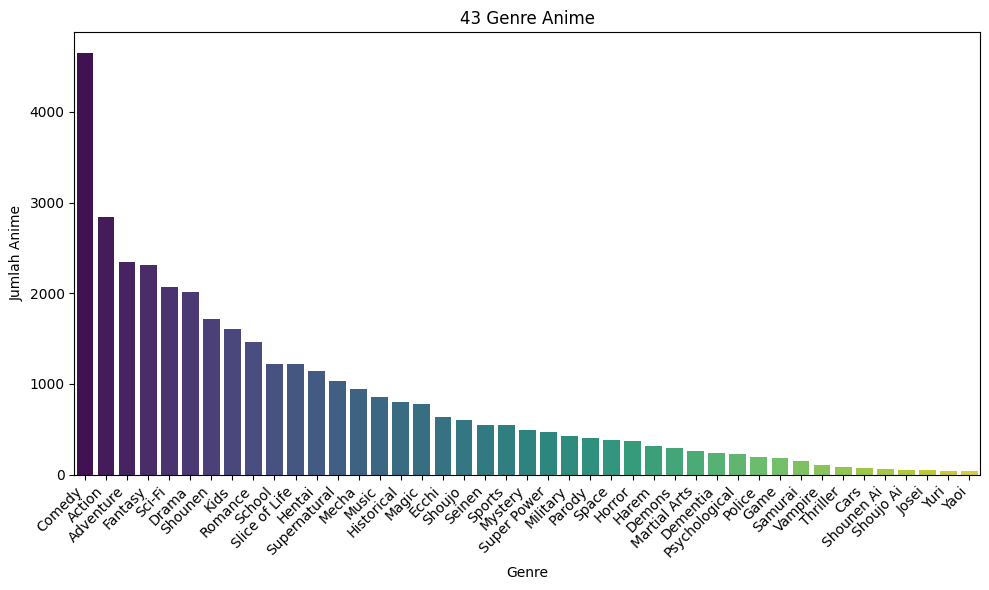

In [ ]:
# Buat visualisasi menggunakan bar plot untuk tiap genre
plt.figure(figsize=(10, 6))
sns.barplot(x=genre_series.head(50).index, y=genre_series.head(50).values, palette='viridis')
plt.title('43 Genre Anime')
plt.xlabel('Genre')
plt.ylabel('Jumlah Anime')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

<ipython-input-25-d6ba96adbb6d>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=anime, x='type', order=anime['type'].value_counts().index, palette='viridis')


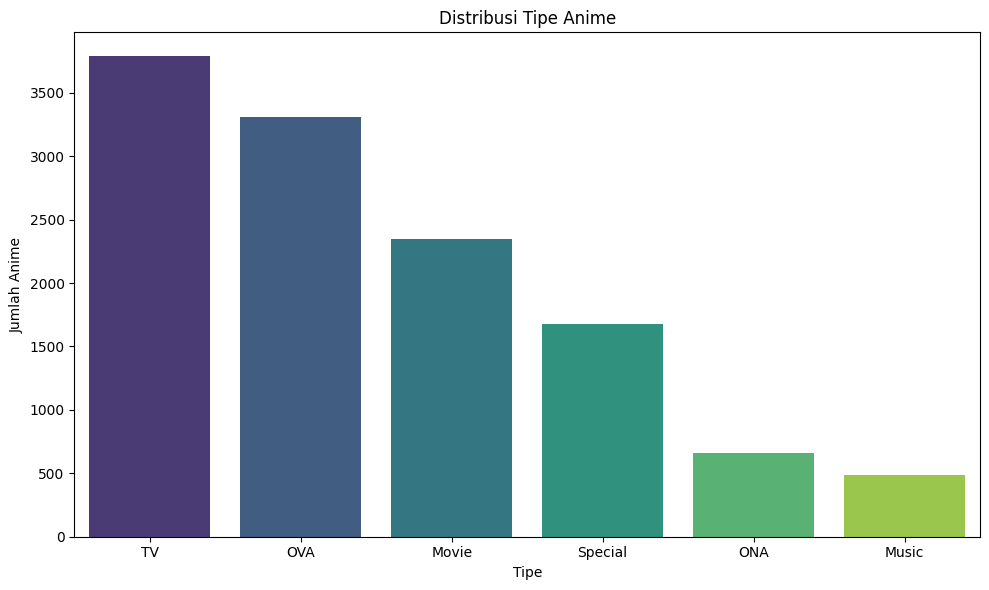

In [ ]:
# Membuat visualisasi distribusi type
plt.figure(figsize=(10, 6))
sns.countplot(data=anime, x='type', order=anime['type'].value_counts().index, palette='viridis')
plt.title('Distribusi Tipe Anime')
plt.xlabel('Tipe')
plt.ylabel('Jumlah Anime')
plt.tight_layout()
plt.show()


Jumlah Anime per Kategori Episode:
episodes
Short          8260
Mini-Series    2604
Long            622
Standard        468
Unknown         340
Name: count, dtype: int64


<ipython-input-26-d7b39df03cfd>:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=episode_category_counts.index, y=episode_category_counts.values, palette='viridis')


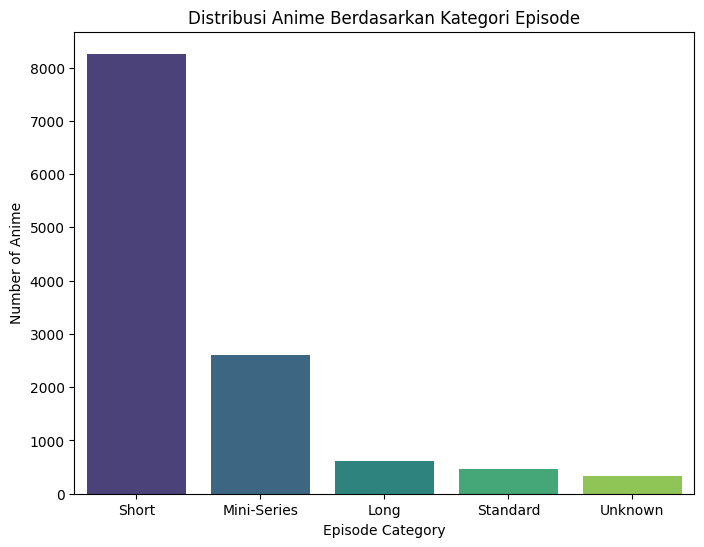

In [ ]:
def categorize_episodes(episodes):
    """Mengategorikan jumlah episode ke dalam kategori Short, Mini-Series, Standard, atau Long."""
    if episodes == 'Unknown':
        return 'Unknown'
    try:
        num_episodes = int(episodes)
        if 1 <= num_episodes <= 10:
            return 'Short'
        elif 11 <= num_episodes <= 30:
            return 'Mini-Series'
        elif 31 <= num_episodes <= 50:
            return 'Standard'
        elif num_episodes >= 51:
            return 'Long'
        else:
            return 'Other' # Mengatasi episode 0 jika ada
    except ValueError:
        return 'Error'

# Hitung jumlah anime di setiap kategori episode
episode_category = anime['episodes'].apply(categorize_episodes)
episode_category_counts = episode_category.value_counts()
print("\nJumlah Anime per Kategori Episode:")
print(episode_category_counts)

# Visualisasi kategori episode
plt.figure(figsize=(8, 6))
sns.barplot(x=episode_category_counts.index, y=episode_category_counts.values, palette='viridis')
plt.title('Distribusi Anime Berdasarkan Kategori Episode')
plt.xlabel('Episode Category')
plt.ylabel('Number of Anime')
plt.show()

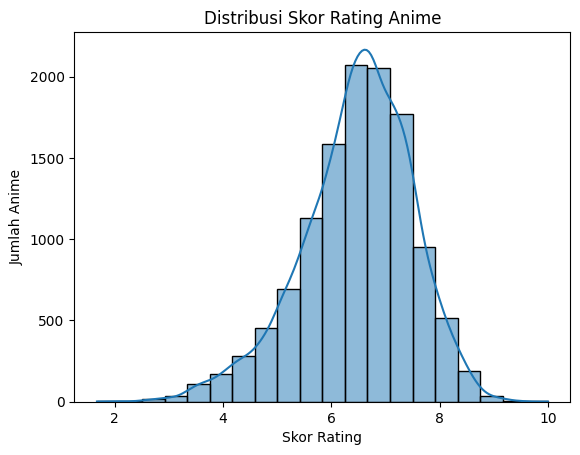

In [ ]:
# Distribusi skor rating pada anime
sns.histplot(anime['rating'].dropna(), bins=20, kde=True)
plt.title("Distribusi Skor Rating Anime")
plt.xlabel("Skor Rating")
plt.ylabel("Jumlah Anime")
plt.show()


Jumlah Anime per Kategori Members:
members
Very Small    4263
Small         4043
Medium        1889
Large         1544
Very Large     524
Ultra           31
Name: count, dtype: int64


<ipython-input-28-b32a80d09ad5>:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=members_category_counts.index, y=members_category_counts.values, palette='viridis')


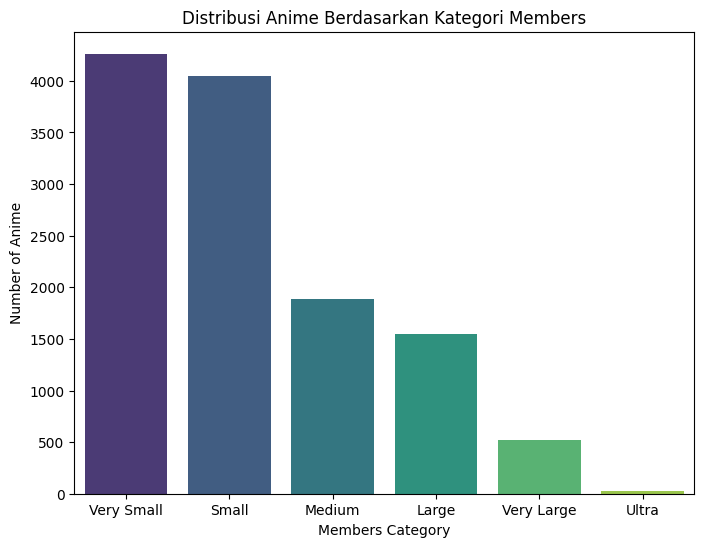

In [ ]:
def categorize_members(members):
    """Mengategorikan jumlah members dengan granularitas lebih baik"""
    if members < 500:
        return 'Very Small'
    elif 500 <= members < 5000:
        return 'Small'
    elif 5000 <= members < 20000:
        return 'Medium'
    elif 20000 <= members < 100000:
        return 'Large'
    elif 100000 <= members < 500000:
        return 'Very Large'
    else:  # ≥500000
        return 'Ultra'

members_category = anime['members'].apply(categorize_members)

# Hitung jumlah anime di setiap kategori members
members_category_counts = members_category.value_counts()
print("\nJumlah Anime per Kategori Members:")
print(members_category_counts)

# Urutkan kategori untuk visualisasi yang lebih baik
order = ['Very Small', 'Small', 'Medium', 'Large', 'Very Large', 'Ultra']
members_category_counts = members_category_counts.reindex(order)


# Visualisasi kategori members
plt.figure(figsize=(8, 6))
sns.barplot(x=members_category_counts.index, y=members_category_counts.values, palette='viridis')
plt.title('Distribusi Anime Berdasarkan Kategori Members')
plt.xlabel('Members Category')
plt.ylabel('Number of Anime')
plt.show()

### Rating

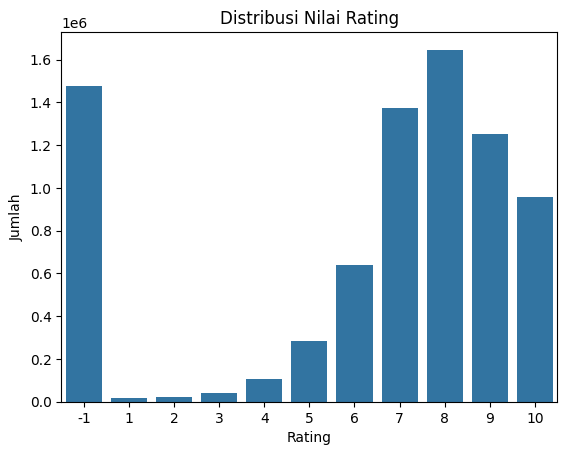

In [ ]:
# Distribusi nilai rating
sns.countplot(x='rating', data=rating.sort_values('rating'))
plt.title("Distribusi Nilai Rating")
plt.xlabel("Rating")
plt.ylabel("Jumlah")
plt.show()

Jumlah User per Segmen:
Light user     36633
Medium user    24329
Power user      8638
Name: count, dtype: int64


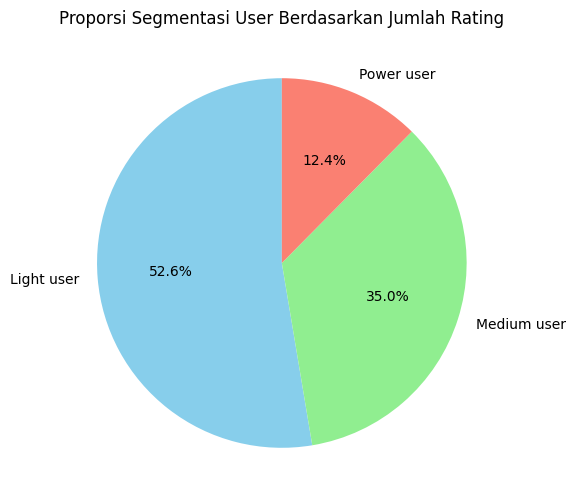

In [ ]:
# Hapus rating -1 (unrated)
filtered_ratings = rating[rating['rating'] != -1]

# Hitung jumlah rating per user
user_ratings_count = filtered_ratings.groupby('user_id').size()

# Fungsi untuk segmentasi user
def segment_user(num_ratings):
    if num_ratings < 50:
        return 'Light user'
    elif 50 <= num_ratings <= 200:
        return 'Medium user'
    else:
        return 'Power user'

# Aplikasikan fungsi segmentasi
user_segments = user_ratings_count.apply(segment_user)

# Hitung proporsi masing-masing segmen
segment_counts = user_segments.value_counts()
segment_proportions = segment_counts / segment_counts.sum()

print("Jumlah User per Segmen:")
print(segment_counts)

# Visualisasi proporsi segmen
plt.figure(figsize=(8, 6))
segment_proportions.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['skyblue', 'lightgreen', 'salmon'])
plt.title('Proporsi Segmentasi User Berdasarkan Jumlah Rating')
plt.ylabel('') # Hapus label y default
plt.show()

Jumlah user yang aktif (ada di dataset rating): 73515
Jumlah user yang memberi rating > 0: 69600
Jumlah user aktif yang tidak memberi rating: 3915


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.11/dist-packages/matplotlib/pyplot.py'>

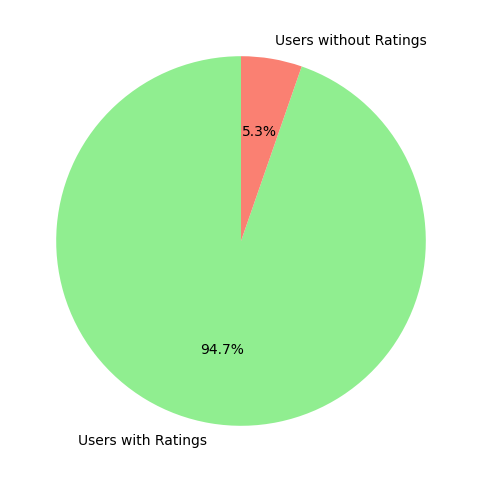

In [ ]:
# Ambil semua user_id dari dataset rating
all_users_in_rating = set(rating['user_id'].unique())

# Ambil user_id yang memberi rating > 0
users_with_ratings = set(rating[rating['rating'] > 0]['user_id'].unique())

# Hitung user yang tidak memberi rating
users_without_ratings = all_users_in_rating - users_with_ratings

print(f"Jumlah user yang aktif (ada di dataset rating): {len(all_users_in_rating)}")
print(f"Jumlah user yang memberi rating > 0: {len(users_with_ratings)}")
print(f"Jumlah user aktif yang tidak memberi rating: {len(users_without_ratings)}")

# Visualisasi user
plt.figure(figsize=(8, 6))
plt.pie([len(users_with_ratings), len(users_without_ratings)], labels=['Users with Ratings', 'Users without Ratings'], autopct='%1.1f%%', startangle=90, colors=['lightgreen', 'salmon'])
plt

**INSIGHT**

---

**Dataset `anime`:**

* **Distribusi Genre:** Genre "Comedy" adalah yang paling banyak muncul, diikuti "Action" dan "Adventure", dengan banyak genre lain yang lebih spesifik menunjukkan keragaman yang luas.
* **Distribusi Tipe Anime:** Tipe "TV" mendominasi jumlah produksi anime, mengungguli format lain seperti OVA dan Movie.
* **Distribusi Kategori Episode:** Kebanyakan anime memiliki jumlah episode yang "Short" (kemungkinan besar termasuk film/OVA), dengan sebagian data episode masih "Unknown".
* **Distribusi Skor Rating Anime (dari sumber):** Skor anime terdistribusi mendekati normal dengan mayoritas anime mendapatkan skor "baik" (sekitar 6.5-7.5), dan skor ekstrem jarang terjadi.
* **Distribusi Kategori Members:** Sebagian besar anime memiliki tingkat popularitas (jumlah members) "Very Small" atau "Small", menunjukkan bahwa popularitas masif hanya dicapai oleh sebagian kecil judul.

**Dataset `rating`:**

* **Distribusi Nilai Rating (oleh pengguna):** Interaksi terbanyak adalah pengguna menandai anime sebagai "ditonton tanpa skor" (-1). Untuk skor yang diberikan, pengguna cenderung memberikan nilai tinggi (7-10).
* **Proporsi Segmentasi User:** Mayoritas pengguna adalah "Light User" (memberikan sedikit skor), sementara "Power User" yang sangat aktif dalam memberi skor hanya merupakan sebagian kecil.
* **Partisipasi Pengguna dalam Memberi Skor:** Sebagian besar pengguna (sekitar 95%) dalam dataset telah memberikan setidaknya satu skor numerik, menunjukkan partisipasi aktif dalam sistem penilaian.

## Multivariate Analysis


Top 10 Anime Paling Banyak Mendapat Rating (rating > 0):
                                        name  rating_count
anime_id                                                  
1535                              Death Note         34226
11757                       Sword Art Online         26310
16498                     Shingeki no Kyojin         25290
1575         Code Geass: Hangyaku no Lelouch         24126
6547                            Angel Beats!         23565
226                               Elfen Lied         23528
20                                    Naruto         22071
5114        Fullmetal Alchemist: Brotherhood         21494
121                      Fullmetal Alchemist         21332
2904      Code Geass: Hangyaku no Lelouch R2         21124


<ipython-input-32-f69c6207088e>:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='rating_count', y='name', data=top_10_popular_anime, palette='viridis')


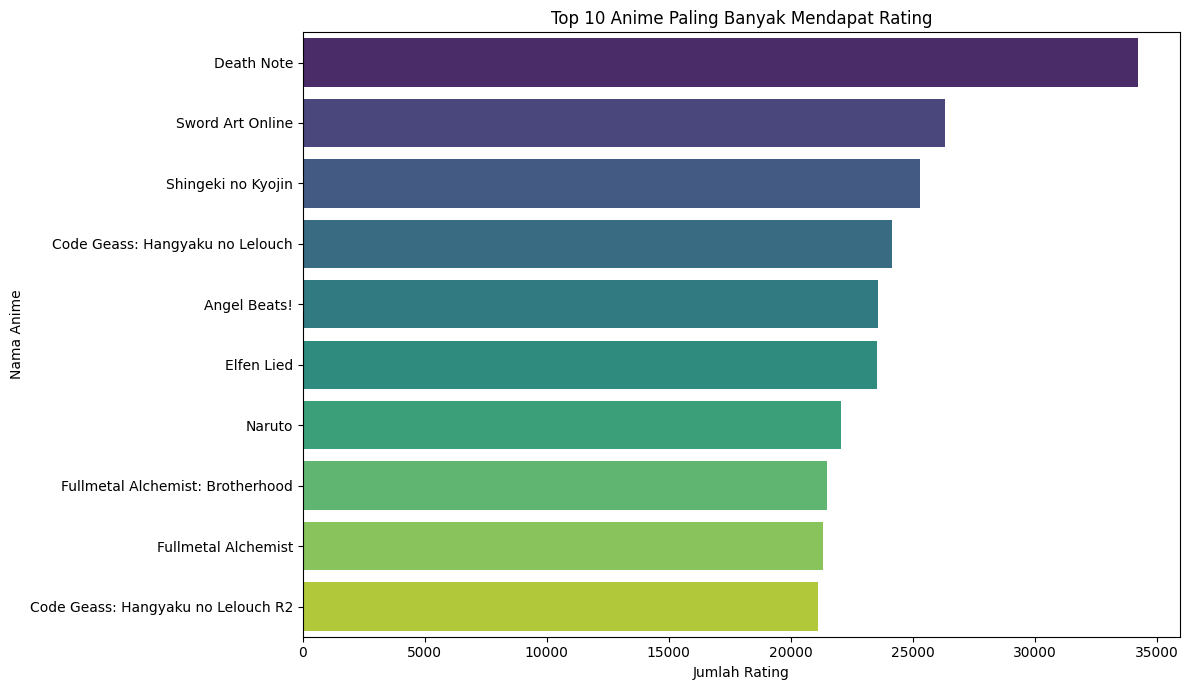

In [ ]:
# Hitung jumlah rating per anime dari data rating yang sudah difilter (rating > 0)
anime_activity_filtered = filtered_ratings['anime_id'].value_counts()

# Gabungkan dengan data anime untuk melihat judul populer
popular_anime_filtered = anime.set_index('anime_id').join(anime_activity_filtered.rename('rating_count'))
popular_anime_filtered = popular_anime_filtered.dropna(subset=['rating_count']) # Hapus anime yang tidak ada di data rating > 0
popular_anime_filtered['rating_count'] = popular_anime_filtered['rating_count'].astype(int) # Konversi ke integer

# Ambil 10 anime teratas berdasarkan jumlah rating
top_10_popular_anime = popular_anime_filtered.sort_values('rating_count', ascending=False).head(10)

print("\nTop 10 Anime Paling Banyak Mendapat Rating (rating > 0):")
print(top_10_popular_anime[['name', 'rating_count']])

# Visualisasi 10 anime terpopuler berdasarkan jumlah rating
plt.figure(figsize=(12, 7))
sns.barplot(x='rating_count', y='name', data=top_10_popular_anime, palette='viridis')
plt.title('Top 10 Anime Paling Banyak Mendapat Rating')
plt.xlabel('Jumlah Rating')
plt.ylabel('Nama Anime')
plt.tight_layout()
plt.show()

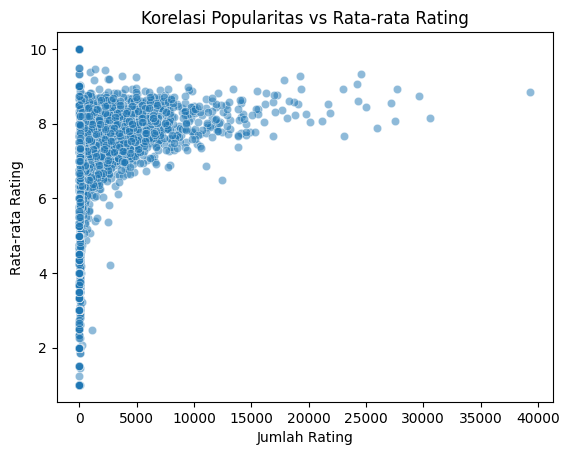

In [ ]:
# Hitung jumlah rating per anime
anime_rating_count = rating.groupby('anime_id').size()

# Hitung rata-rata rating per anime dengan menyaring rating -1 (unrated)
anime_mean_rating = rating[rating['rating'] > 0].groupby('anime_id')['rating'].mean()

# Membuat DataFrame gabungan untuk analisis korelasi
correlation_df = pd.DataFrame({
    'rating_count': anime_rating_count,
    'mean_rating': anime_mean_rating
}).dropna()

# Visualisasi scatter plot korelasi
sns.scatterplot(x='rating_count', y='mean_rating', data=correlation_df, alpha=0.5)
plt.title("Korelasi Popularitas vs Rata-rata Rating")
plt.xlabel("Jumlah Rating")
plt.ylabel("Rata-rata Rating")

plt.show()

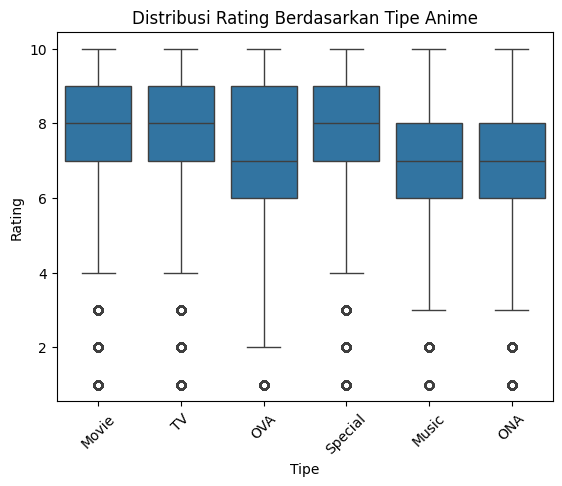

In [ ]:
# Distribusi rating berdasarkan tipe anime
anime_type_rating = anime[['anime_id', 'type']].merge(
    rating[rating['rating'] > 0], on='anime_id')

sns.boxplot(x='type', y='rating', data=anime_type_rating)
plt.title("Distribusi Rating Berdasarkan Tipe Anime")
plt.xlabel("Tipe")
plt.ylabel("Rating")
plt.xticks(rotation=45)
plt.show()

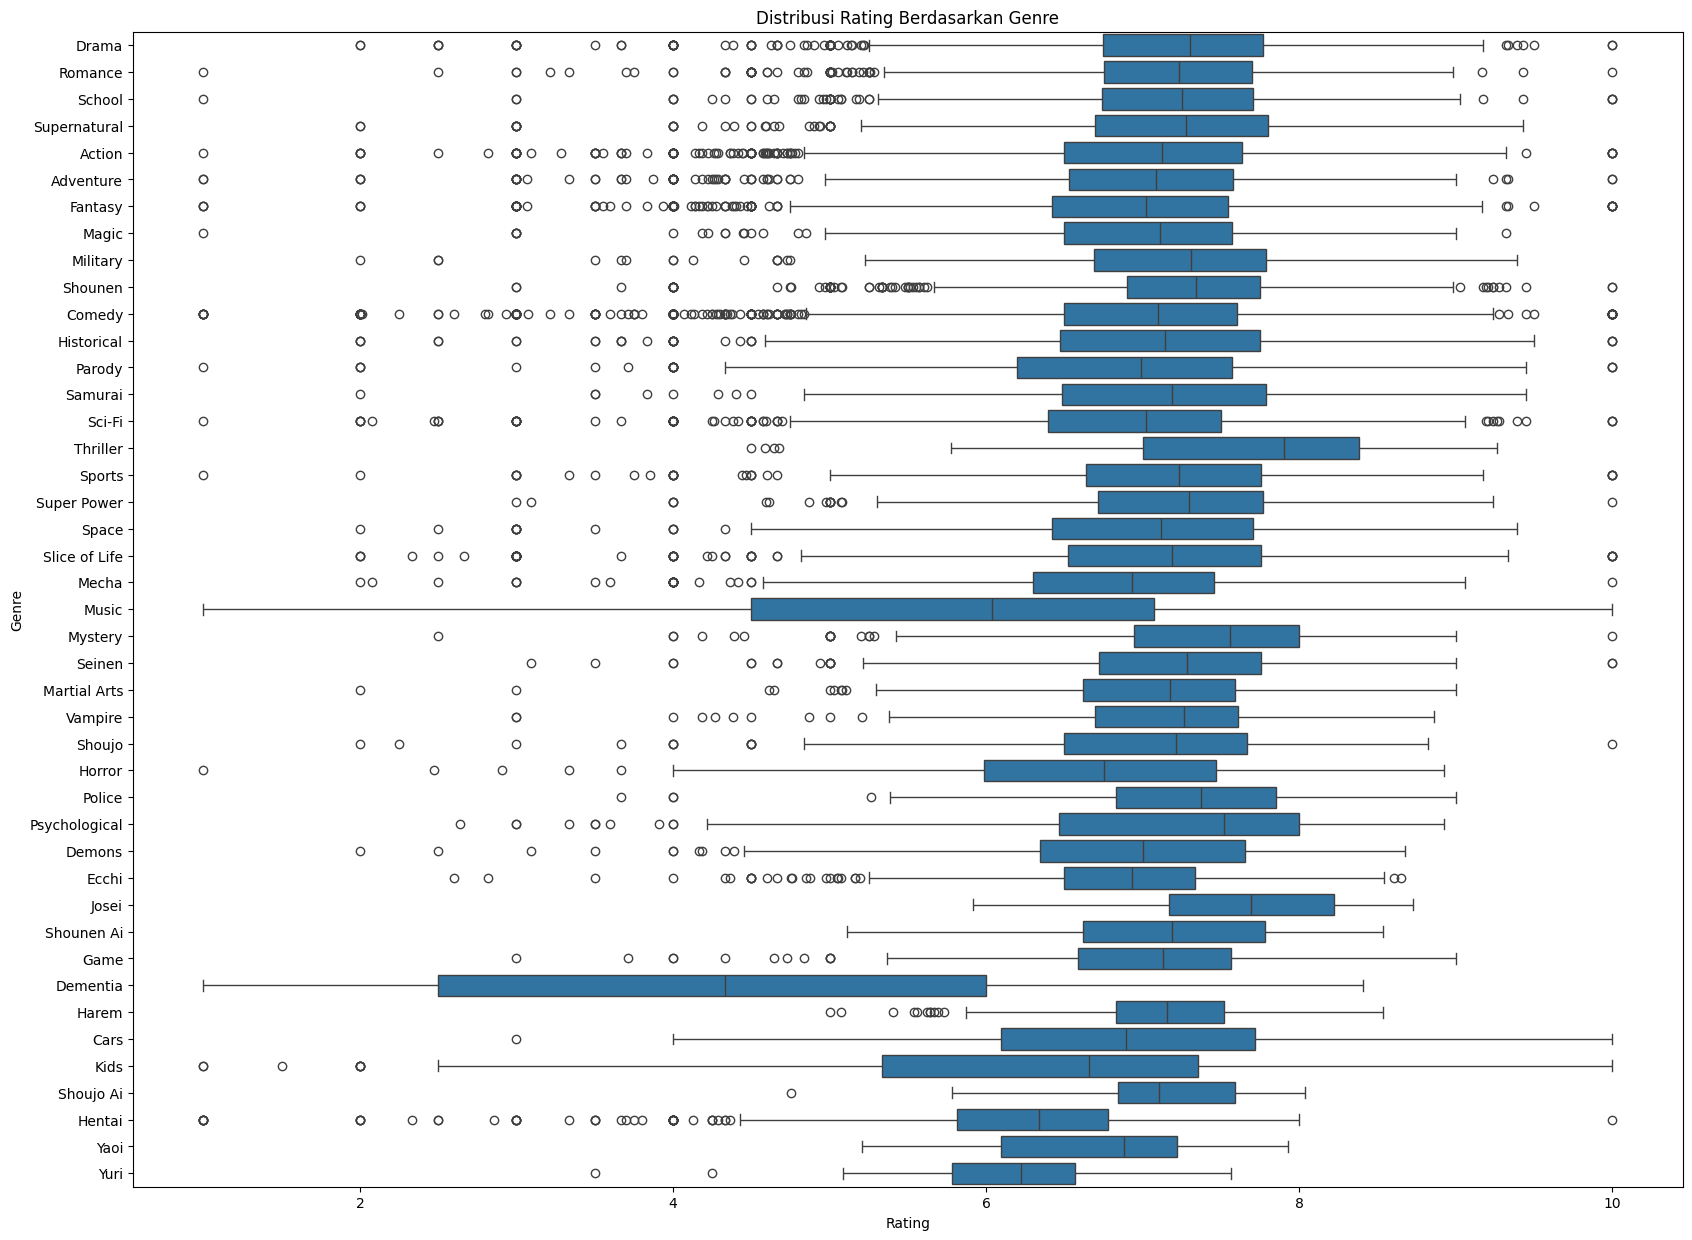

In [ ]:
# Ambil rating rata-rata per anime
anime_mean_rating = rating[rating['rating'] > 0].groupby('anime_id')['rating'].mean().reset_index()
anime_genre_rating = anime[['anime_id', 'genre']].merge(anime_mean_rating, on='anime_id')
genre_ratings = []

for _, row in anime_genre_rating.dropna().iterrows():
    for g in row['genre'].split(', '):
        genre_ratings.append((g, row['rating']))

genre_rating_df = pd.DataFrame(genre_ratings, columns=['genre', 'rating'])

plt.figure(figsize=(20, 15))
sns.boxplot(x='rating', y='genre', data=genre_rating_df)
plt.title("Distribusi Rating Berdasarkan Genre")
plt.xlabel("Rating")
plt.ylabel("Genre")
plt.show()

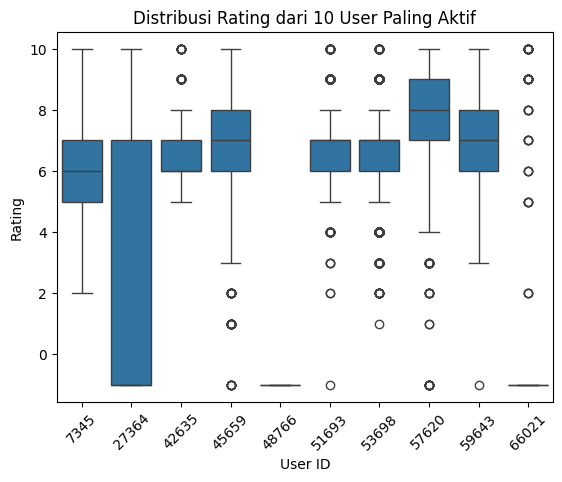

In [ ]:
# User dengan jumlah rating terbanyak
top_users = rating['user_id'].value_counts().head(10)

top_users_df = rating[rating['user_id'].isin(top_users.index)]
sns.boxplot(x='user_id', y='rating', data=top_users_df)
plt.title("Distribusi Rating dari 10 User Paling Aktif")
plt.xlabel("User ID")
plt.ylabel("Rating")
plt.xticks(rotation=45)
plt.show()

<ipython-input-38-0a333795f640>:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='members_category', y='rating', data=anime_members_rating, order=order, palette='viridis')


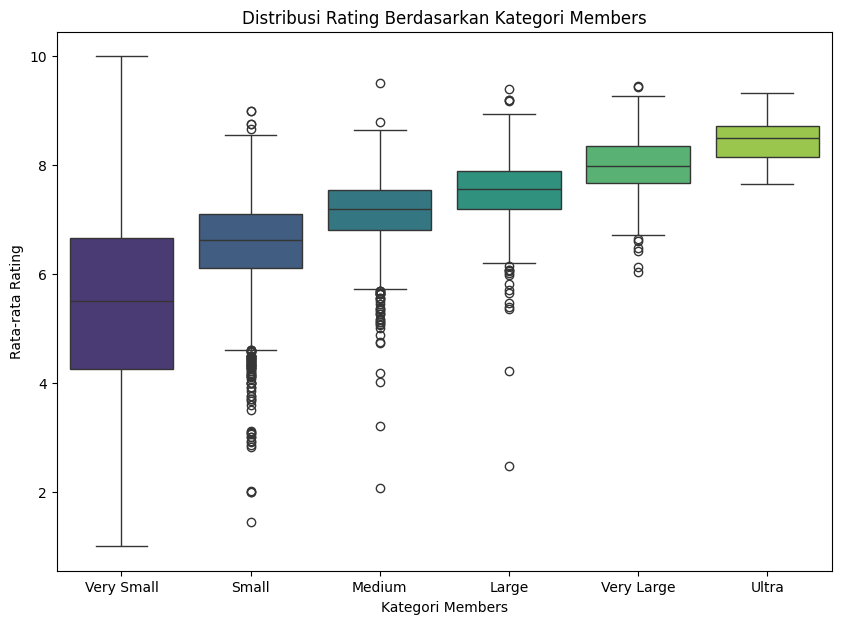

In [ ]:
# Hitung rating rata-rata per anime dengan menyaring rating -1 (unrated)
anime_mean_rating = rating[rating['rating'] > 0].groupby('anime_id')['rating'].mean().reset_index()

# Gabungkan data anime dengan rata-rata rating dan kategori members yang sudah dibuat
anime_members_rating = anime[['anime_id', 'members']].merge(anime_mean_rating, on='anime_id')

# Aplikasikan fungsi kategorisasi members
anime_members_rating['members_category'] = anime_members_rating['members'].apply(categorize_members)

# Visualisasi distribusi rating berdasarkan kategori members
plt.figure(figsize=(10, 7))
sns.boxplot(x='members_category', y='rating', data=anime_members_rating, order=order, palette='viridis')
plt.title("Distribusi Rating Berdasarkan Kategori Members")
plt.xlabel("Kategori Members")
plt.ylabel("Rata-rata Rating")
plt.show()

<ipython-input-39-f9093236de5b>:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='episode_category', y='rating', data=anime_episodes_rating_filtered, order=[cat for cat in episode_order if cat in anime_episodes_rating_filtered['episode_category'].unique()], palette='viridis')


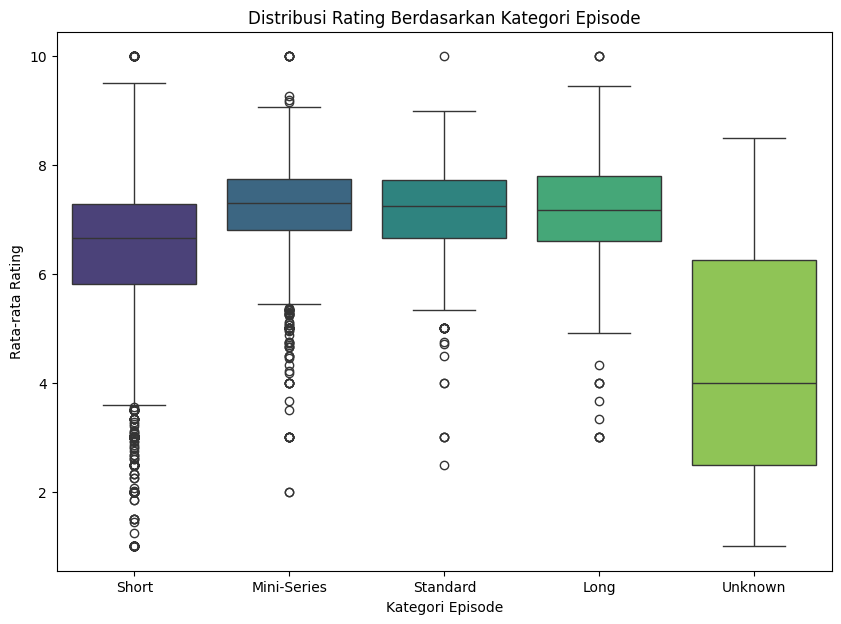

In [ ]:
# Ambil rata-rata rating per anime dengan menyaring rating -1 (unrated)
anime_mean_rating = rating[rating['rating'] > 0].groupby('anime_id')['rating'].mean().reset_index()

# Gabungkan data anime dengan rata-rata rating dan kategori episode yang sudah dibuat
anime_episodes_rating = anime[['anime_id', 'episodes']].merge(anime_mean_rating, on='anime_id')

# Aplikasikan fungsi kategorisasi episode
anime_episodes_rating['episode_category'] = anime_episodes_rating['episodes'].apply(categorize_episodes)

# Urutkan kategori episode untuk visualisasi yang lebih baik (kecuali Unknown)
episode_order = ['Short', 'Mini-Series', 'Standard', 'Long', 'Other', 'Unknown']
anime_episodes_rating_filtered = anime_episodes_rating[anime_episodes_rating['episode_category'] != 'Error'] # Hapus kategori 'Error' jika ada

# Visualisasi distribusi rating berdasarkan kategori episode
plt.figure(figsize=(10, 7))
sns.boxplot(x='episode_category', y='rating', data=anime_episodes_rating_filtered, order=[cat for cat in episode_order if cat in anime_episodes_rating_filtered['episode_category'].unique()], palette='viridis')
plt.title("Distribusi Rating Berdasarkan Kategori Episode")
plt.xlabel("Kategori Episode")
plt.ylabel("Rata-rata Rating")
plt.show()

**INSIGHT**

---

* **Anime Terpopuler (Rating Terbanyak):**
    "Death Note" dominan sebagai anime yang paling banyak diulas. "Sword Art Online" dan "Shingeki no Kyojin" juga populer, namun dengan jumlah ulasan lebih sedikit.

* **Korelasi Popularitas & Rata-rata Rating:**
    Anime populer (banyak ulasan) cenderung memiliki rata-rata rating lebih tinggi. Anime kurang populer variasinya lebih lebar, sedangkan yang sangat populer umumnya memiliki rating baik (mayoritas >6.0).

* **Rating Berdasarkan Tipe Anime:**
    "Movie" dan "TV" memiliki median rating tertinggi (~8.0-9.0). "OVA" dan "ONA" sedikit di bawahnya dengan variasi kualitas lebih besar. "Music" cenderung terendah.

* **Rating Berdasarkan Genre:**
    Genre mainstream ("Drama", "Romance", "School", "Supernatural") memiliki median rating tinggi dan stabil (~7.5-8.5). "Thriller" dan "Mystery" sebarannya lebih lebar; "Dementia" atau "Music" sangat bervariasi.

* **Rating dari 10 User Teraktif:**
    Mayoritas 10 user teraktif memberi rating di atas rata-rata (umumnya 6-8). Beberapa menunjukkan pola rating ekstrem (rendah), mengindikasikan kritikus atau anomali.

* **Rating Berdasarkan Jumlah Members:**
    Median rating anime meningkat seiring jumlah anggota. Anime dengan >10.000 members ("Very Large" - "Ultra") umumnya memiliki median rating tertinggi (~8.0-8.5).

* **Rating Berdasarkan Jumlah Episode:**
    Anime durasi "Long" dan "Standard" memiliki median rating lebih tinggi (~7.0-7.5+). Kategori "Short" lebih rendah; episode "Unknown" sangat bervariasi dan cenderung rendah.

# Data Preparation

## Anime

### Handling Missing Values

In [5]:
# Menghapus baris dengan nilai null pada kolom 'genre', 'type', dan 'rating'
anime_cleaned = anime.dropna(subset=['genre', 'type', 'rating'])

# Memeriksa kembali jumlah nilai yang hilang setelah penghapusan
print("Jumlah nilai null setelah penghapusan:")
print(anime_cleaned.isnull().sum())

# Informasi dataset setelah penghapusan
print("\nInformasi dataset setelah penghapusan:")
anime_cleaned.info()

Jumlah nilai null setelah penghapusan:
anime_id    0
name        0
genre       0
type        0
episodes    0
rating      0
members     0
dtype: int64

Informasi dataset setelah penghapusan:
<class 'pandas.core.frame.DataFrame'>
Index: 12017 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12017 non-null  int64  
 1   name      12017 non-null  object 
 2   genre     12017 non-null  object 
 3   type      12017 non-null  object 
 4   episodes  12017 non-null  object 
 5   rating    12017 non-null  float64
 6   members   12017 non-null  int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 751.1+ KB


**Insight Persiapan Data: Penanganan Nilai Hilang**

---

* Data telah dibersihkan dengan **menghapus baris** yang memiliki nilai hilang (*missing values*) pada kolom-kolom krusial seperti **`genre`**, **`type`**, dan **`rating`**.

* Setelah proses ini, dataset `anime_cleaned` kini **bebas dari nilai null** di semua kolomnya. Jumlah entri data berkurang menjadi **12.017 anime**, yang siap untuk analisis dan pemodelan lebih lanjut.

### Handling Invalid Values

In [6]:
# Konversi nilai "Unknown" menjadi NaN (Not a Number)
anime_cleaned['episodes'] = anime_cleaned['episodes'].replace('Unknown', np.nan)
print("Nilai unik setelah replace:", anime_cleaned['episodes'].unique())

Nilai unik setelah replace: ['1' '64' '51' '24' '10' '148' '110' '13' '201' '25' '22' '75' '4' '26'
 '12' '27' '43' '74' '37' '2' '11' '99' nan '39' '101' '47' '50' '62' '33'
 '112' '23' '3' '94' '6' '8' '14' '7' '40' '15' '203' '77' '291' '120'
 '102' '96' '38' '79' '175' '103' '70' '153' '45' '5' '21' '63' '52' '28'
 '145' '36' '69' '60' '178' '114' '35' '61' '34' '109' '20' '9' '49' '366'
 '97' '48' '78' '358' '155' '104' '113' '54' '167' '161' '42' '142' '31'
 '373' '220' '46' '195' '17' '1787' '73' '147' '127' '16' '19' '98' '150'
 '76' '53' '124' '29' '115' '224' '44' '58' '93' '154' '92' '67' '172'
 '86' '30' '276' '59' '72' '330' '41' '105' '128' '137' '56' '55' '65'
 '243' '193' '18' '191' '180' '91' '192' '66' '182' '32' '164' '100' '296'
 '694' '95' '68' '117' '151' '130' '87' '170' '119' '84' '108' '156' '140'
 '331' '305' '300' '510' '200' '88' '1471' '526' '143' '726' '136' '1818'
 '237' '1428' '365' '163' '283' '71' '260' '199' '225' '312' '240' '1306'
 '1565' '773' '127

<ipython-input-6-12a0b4c3120d>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  anime_cleaned['episodes'] = anime_cleaned['episodes'].replace('Unknown', np.nan)


In [7]:
# Konversi tipe data kolom 'episodes' numerik float
anime_cleaned['episodes'] = pd.to_numeric(anime_cleaned['episodes'], errors='coerce')

# Hapus nilai NaN di kolom 'episodes'
anime_cleaned = anime_cleaned.dropna(subset=['episodes'])

# Mengubah tipe data kolom 'episodes' numerik int
anime_cleaned['episodes'] = anime_cleaned['episodes'].astype(int)
print("\nSetelah menghapus nilai NaN di kolom 'episodes':")
anime_cleaned.info()
print(anime_cleaned['episodes'].unique())


Setelah menghapus nilai NaN di kolom 'episodes':
<class 'pandas.core.frame.DataFrame'>
Index: 11830 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  11830 non-null  int64  
 1   name      11830 non-null  object 
 2   genre     11830 non-null  object 
 3   type      11830 non-null  object 
 4   episodes  11830 non-null  int64  
 5   rating    11830 non-null  float64
 6   members   11830 non-null  int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 739.4+ KB
[   1   64   51   24   10  148  110   13  201   25   22   75    4   26
   12   27   43   74   37    2   11   99   39  101   47   50   62   33
  112   23    3   94    6    8   14    7   40   15  203   77  291  120
  102   96   38   79  175  103   70  153   45    5   21   63   52   28
  145   36   69   60  178  114   35   61   34  109   20    9   49  366
   97   48   78  358  155  104  113   54  167  161   42  142   31  373
  220 

<ipython-input-7-7d0f69f33d9a>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  anime_cleaned['episodes'] = pd.to_numeric(anime_cleaned['episodes'], errors='coerce')
<ipython-input-7-7d0f69f33d9a>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  anime_cleaned['episodes'] = anime_cleaned['episodes'].astype(int)


**Insight Persiapan Data: Penanganan Nilai Tidak Valid pada Kolom 'episodes'**

---

* Nilai teks **"Unknown"** diubah menjadi `NaN` (Not a Number).
* Kolom dikonversi menjadi tipe **numerik**, memastikan semua entri adalah angka.
* Baris dengan nilai `NaN` (awalnya "Unknown") pada kolom `episodes` kemudian **dihapus**.
* Akhirnya, tipe data kolom `episodes` diubah menjadi **integer**.
* Hasilnya, kolom `episodes` kini berisi data numerik yang konsisten (jumlah episode dalam bentuk bilangan bulat), dan jumlah entri data dalam dataset menjadi **11.830 anime**.

### Normalization Features numeric

In [8]:
# Inisialisasi MinMaxScaler
scaler = MinMaxScaler()

# Terapkan scaling pada kolom 'episodes', 'members', dan 'rating'
anime_cleaned[['episodes_normalized', 'members_normalized', 'rating_normalized']] = scaler.fit_transform(
    anime_cleaned[['episodes','members', 'rating']]
)

# Testing
print("DataFrame setelah normalisasi:")
print(anime_cleaned[['anime_id', 'name',
                     'episodes', 'episodes_normalized',
                     'members', 'members_normalized',
                     'rating', 'rating_normalized'
                     ]].head())

# Testing info
anime_cleaned.info()

DataFrame setelah normalisasi:
   anime_id                              name  episodes  episodes_normalized  \
0     32281                    Kimi no Na wa.         1             0.000000   
1      5114  Fullmetal Alchemist: Brotherhood        64             0.034673   
2     28977                          Gintama°        51             0.027518   
3      9253                       Steins;Gate        24             0.012658   
4      9969                     Gintama&#039;        51             0.027518   

   members  members_normalized  rating  rating_normalized  
0   200630            0.197867    9.37           0.924370  
1   793665            0.782769    9.26           0.911164  
2   114262            0.112683    9.25           0.909964  
3   673572            0.664323    9.17           0.900360  
4   151266            0.149180    9.16           0.899160  
<class 'pandas.core.frame.DataFrame'>
Index: 11830 entries, 0 to 12293
Data columns (total 10 columns):
 #   Column             

**Insight Persiapan Data: Normalisasi Fitur Numerik**

---

Fitur numerik **`episodes`**, **`members`**, dan **`rating`** telah dinormalisasi menggunakan `MinMaxScaler`.  rescaling

* Proses ini mengubah rentang nilai pada masing-masing kolom tersebut menjadi **skala standar antara 0 dan 1**.
* Hasil normalisasi disimpan dalam kolom baru: **`episodes_normalized`**, **`members_normalized`**, dan **`rating_normalized`**.

Tujuannya adalah untuk **menyamakan skala fitur-fitur** tersebut. Ini penting agar fitur dengan rentang nilai yang lebih besar tidak mendominasi atau memberikan bobot yang tidak proporsional dalam perhitungan model. Dataset kini memiliki fitur-fitur numerik yang siap digunakan dengan skala yang seragam.

### Vektorisasi Features categorical

#### Type

In [9]:
# One-Hot Encoding untuk type
type_dummies = pd.get_dummies(anime_cleaned['type'], prefix='type', dtype=int)
anime_cleaned = pd.concat([anime_cleaned, type_dummies], axis=1)

# Testing
anime_cleaned.info()
anime_cleaned

<class 'pandas.core.frame.DataFrame'>
Index: 11830 entries, 0 to 12293
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   anime_id             11830 non-null  int64  
 1   name                 11830 non-null  object 
 2   genre                11830 non-null  object 
 3   type                 11830 non-null  object 
 4   episodes             11830 non-null  int64  
 5   rating               11830 non-null  float64
 6   members              11830 non-null  int64  
 7   episodes_normalized  11830 non-null  float64
 8   members_normalized   11830 non-null  float64
 9   rating_normalized    11830 non-null  float64
 10  type_Movie           11830 non-null  int64  
 11  type_Music           11830 non-null  int64  
 12  type_ONA             11830 non-null  int64  
 13  type_OVA             11830 non-null  int64  
 14  type_Special         11830 non-null  int64  
 15  type_TV              11830 non-null  int6

,anime_id,name,genre,type,episodes,rating,members,episodes_normalized,members_normalized,rating_normalized,type_Movie,type_Music,type_ONA,type_OVA,type_Special,type_TV
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630,0.000000,0.197867,0.924370,1,0,0,0,0,0
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665,0.034673,0.782769,0.911164,0,0,0,0,0,1
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262,0.027518,0.112683,0.909964,0,0,0,0,0,1
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572,0.012658,0.664323,0.900360,0,0,0,0,0,1
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266,0.027518,0.149180,0.899160,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12289,9316,Toushindai My Lover: Minami tai Mecha-Minami,Hentai,OVA,1,4.15,211,0.000000,0.000196,0.297719,0,0,0,1,0,0
12290,5543,Under World,Hentai,OVA,1,4.28,183,0.000000,0.000169,0.313325,0,0,0,1,0,0
12291,5621,Violence Gekiga David no Hoshi,Hentai,OVA,4,4.88,219,0.001651,0.000204,0.385354,0,0,0,1,0,0
12292,6133,Violence Gekiga Shin David no Hoshi: Inma Dens...,Hentai,OVA,1,4.98,175,0.000000,0.000161,0.397359,0,0,0,1,0,0


**Insight Persiapan Data: Vektorisasi Fitur Kategorikal (type)**

---

* **One-Hot Encoding** diterapkan pada kolom `type`. Karena kolom sederhana dengan sedikit nilai unik dan tidak memiliki urutan.
* Setiap nilai unik dalam `type` (misalnya, "Movie", "TV") diubah menjadi **kolom biner baru** (contoh: `type_Movie`, `type_TV`). Nilai 1 menandakan anime tersebut memiliki tipe tersebut, 0 jika tidak.
* Ini mengubah representasi `type` menjadi format numerik yang dapat dipahami model.

#### Genre

In [10]:
# Mendefinisikan fungsi pembersihan dan pemisahan
def clean_and_split_genre(genre_str):
    if pd.isna(genre_str):
        return []
    # split di koma, strip spasi, ubah ke lowercase, buang elemen kosong
    return [g.strip().lower() for g in genre_str.split(',') if g.strip()]

# Terapkan fungsi ke kolom genre
anime_cleaned['genre_list'] = anime_cleaned['genre'].apply(clean_and_split_genre)

# Testing
print(anime_cleaned[['name', 'genre', 'genre_list']].head(10))
anime_cleaned.info()
anime_cleaned.head()

                                                name  \
0                                     Kimi no Na wa.   
1                   Fullmetal Alchemist: Brotherhood   
2                                           Gintama°   
3                                        Steins;Gate   
4                                      Gintama&#039;   
5  Haikyuu!!: Karasuno Koukou VS Shiratorizawa Ga...   
6                             Hunter x Hunter (2011)   
7                               Ginga Eiyuu Densetsu   
8  Gintama Movie: Kanketsu-hen - Yorozuya yo Eien...   
9                           Gintama&#039;: Enchousen   

                                               genre  \
0               Drama, Romance, School, Supernatural   
1  Action, Adventure, Drama, Fantasy, Magic, Mili...   
2  Action, Comedy, Historical, Parody, Samurai, S...   
3                                   Sci-Fi, Thriller   
4  Action, Comedy, Historical, Parody, Samurai, S...   
5             Comedy, Drama, School, Shounen, S

,anime_id,name,genre,type,episodes,rating,members,episodes_normalized,members_normalized,rating_normalized,type_Movie,type_Music,type_ONA,type_OVA,type_Special,type_TV,genre_list
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630,0.000000,0.197867,0.924370,1,0,0,0,0,0,"[drama, romance, school, supernatural]"
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665,0.034673,0.782769,0.911164,0,0,0,0,0,1,"[action, adventure, drama, fantasy, magic, mil..."
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262,0.027518,0.112683,0.909964,0,0,0,0,0,1,"[action, comedy, historical, parody, samurai, ..."
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572,0.012658,0.664323,0.900360,0,0,0,0,0,1,"[sci-fi, thriller]"
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266,0.027518,0.149180,0.899160,0,0,0,0,0,1,"[action, comedy, historical, parody, samurai, ..."


**Insight Persiapan Data: Pembersihan dan Strukturisasi Kolom Genre menjadi Daftar (List)**

---

* String genre (yang bisa berisi beberapa genre dipisahkan koma) **dibersihkan dan dipisahkan**.
* Proses ini melibatkan: pemisahan berdasarkan koma, penghapusan spasi berlebih, konversi ke huruf kecil, dan penanganan nilai kosong.
* Hasilnya adalah kolom baru **`genre_list`** yang berisi **daftar (list) string genre** untuk setiap anime.

In [11]:
# Mendefinisikan fungsi untuk memformat list genre menjadi string tunggal untuk TF-IDF
def prepare_genre_for_tfidf(genre_list):
    processed_genres = []
    for g in genre_list:
        processed_genres.append(g.replace(' ', '_')) # Ganti spasi dengan underscore
    return ' '.join(processed_genres) # Gabungkan kembali menjadi satu string dipisahkan spasi

# Terapkan fungsi ke kolom genre
anime_cleaned['genre_tfidf_string'] = anime_cleaned['genre_list'].apply(prepare_genre_for_tfidf)

# Inisialisasi TfidfVectorizer TANPA tokenizer kustom
tfidf = TfidfVectorizer() # tokenizer=None atau default
tfidf_matrix = tfidf.fit_transform(anime_cleaned['genre_tfidf_string'])

# Testing
print("Shape of TF-IDF matrix:", tfidf_matrix.shape)
print("Fitur genre setelah perbaikan tokenisasi (TF-IDF):", tfidf.get_feature_names_out())

Shape of TF-IDF matrix: (11830, 44)
Fitur genre setelah perbaikan tokenisasi (TF-IDF): ['action' 'adventure' 'cars' 'comedy' 'dementia' 'demons' 'drama' 'ecchi'
 'fantasy' 'fi' 'game' 'harem' 'hentai' 'historical' 'horror' 'josei'
 'kids' 'magic' 'martial_arts' 'mecha' 'military' 'music' 'mystery'
 'parody' 'police' 'psychological' 'romance' 'samurai' 'school' 'sci'
 'seinen' 'shoujo' 'shoujo_ai' 'shounen' 'shounen_ai' 'slice_of_life'
 'space' 'sports' 'super_power' 'supernatural' 'thriller' 'vampire' 'yaoi'
 'yuri']


**Insight Persiapan Data: Vektorisasi Kolom Genre Menggunakan TF-IDF**

---

* **Persiapan Genre**: Genre multi-kata (misal, "martial arts") diubah menjadi satu token (misal, "martial\_arts") dan digabung menjadi string per anime.
* **TF-IDF Diterapkan**: `TfidfVectorizer` mengubah string genre ini menjadi **matriks numerik (`tfidf_matrix`)**. Karena kolom genre bersifat multi-label dan tekstual.
* **Hasil**: Matriks (11830 anime x 44 genre) dengan skor TF-IDF untuk tiap genre, siap untuk analisis kemiripan.

In [12]:
# Mengubah vektor tf-idf dalam bentuk matriks dengan fungsi todense()
tfidf_matrix.todense()

matrix([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
         0.        ],
        [0.29436493, 0.31602086, 0.        , ..., 0.        , 0.        ,
         0.        ],
        [0.2508832 , 0.        , 0.        , ..., 0.        , 0.        ,
         0.        ],
        ...,
        [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
         0.        ],
        [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
         0.        ],
        [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
         0.        ]])

**Insight Persiapan Data: Konversi Matriks TF-IDF ke Format Dense**

---

Operasi `tfidf_matrix.todense()` mengubah matriks TF-IDF dari format *sparse* (hemat memori, hanya menyimpan nilai non-nol) menjadi matriks *dense* (padat) NumPy.  dense.

In [13]:
# Membuat dataframe untuk melihat tf-idf matrix
# Kolom diisi dengan genre anime
# Baris diisi dengan nama anime

print("\nSample of TF-IDF DataFrame:")
pd.DataFrame(
    tfidf_matrix.todense(),
    columns=tfidf.get_feature_names_out(),
    index=anime_cleaned.name
).sample(10, axis=1).sample(10, axis=0)


Sample of TF-IDF DataFrame:


,super_power,harem,drama,demons,music,psychological,supernatural,action,school,samurai
name,,,,,,,,,,
Kenzen Robo Daimidaler,0.00000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0
Ao no 6-gou,0.00000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.318143,0.0,0.0
Kibun Kibun,0.00000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0
Akiko,0.00000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0
Baoh Raihousha,0.44751,0.0,0.000000,0.0,0.0,0.0,0.000000,0.257271,0.0,0.0
Tabisuru Nuigurumi: Traveling Daru,0.00000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0
Bleach Movie 2: The DiamondDust Rebellion - Mou Hitotsu no Hyourinmaru,0.00000,0.0,0.000000,0.0,0.0,0.0,0.597476,0.422661,0.0,0.0
Ghost in the Shell: Stand Alone Complex - Solid State Society 3D,0.00000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0
Mobile Suit Gundam Seed,0.00000,0.0,0.294193,0.0,0.0,0.0,0.000000,0.259234,0.0,0.0


**Insight Persiapan Data: DataFrame Sampel dari Matriks TF-IDF**

---

Kode ini membuat **DataFrame Pandas** dari matriks TF-IDF yang sebelumnya telah diubah menjadi format *dense* (padat).

* **Tujuan**: Menyajikan skor TF-IDF dalam format tabel agar lebih mudah diinspeksi dan dipahami.
* **Struktur DataFrame**:
    * **Baris (`index`)**: Nama-nama anime (diambil dari `anime_cleaned.name`).
    * **Kolom (`columns`)**: Fitur-fitur genre yang dihasilkan oleh TF-IDF (diambil dari `tfidf.get_feature_names_out()`).
    * **Nilai**: Skor TF-IDF yang menunjukkan seberapa penting suatu genre (kolom) untuk anime tertentu (baris).
* **`.sample(10, axis=1).sample(10, axis=0)`**: Kode ini mengambil **sampel acak** dari DataFrame tersebut:
    * Pertama, dipilih 10 genre (kolom) secara acak.
    * Kemudian, dari 10 genre tersebut, dipilih 10 anime (baris) secara acak.
    * Ini berguna untuk melihat cuplikan kecil dari data tanpa harus menampilkan keseluruhan DataFrame yang bisa sangat besar.
* Output menunjukkan di mana nilai 0.0 berarti genre tersebut tidak signifikan atau tidak ada pada anime tersebut, sementara nilai yang lebih tinggi (seperti 0.584701 atau 0.811249) menunjukkan asosiasi yang lebih kuat antara anime dan genre tersebut.

### Merge Preprocessed Features

In [14]:
# Ekstrak fitur One-Hot Encoding untuk type
type_features = anime_cleaned[['type_Movie', 'type_Music', 'type_ONA', 'type_OVA', 'type_Special', 'type_TV']].values

# Ekstrak fitur numerik yang dinormalisasi untuk episodes
episode_features = anime_cleaned[['episodes_normalized']].values

# Ekstrak fitur numerik yang dinormalisasi untuk members
member_features = anime_cleaned[['members_normalized']].values

# Ekstrak fitur numerik yang dinormalisasi untuk rating
rating_features = anime_cleaned[['rating_normalized']].values

# Gabungkan semua fitur
all_content_features = hstack([tfidf_matrix, type_features, episode_features, member_features, rating_features])

print("Dimensi Matriks Fitur Konten Lengkap:", all_content_features.shape)

Dimensi Matriks Fitur Konten Lengkap: (11830, 53)


**Insight Persiapan Data: Penggabungan Fitur Konten**

---

Proses ini menyatukan semua representasi fitur anime yang sudah melewati tahap preprocessing ke dalam satu matriks tunggal (`all_content_features`):

* **Ekstraksi Fitur Individual**:
    * `type_features`: Fitur **tipe anime** yang sudah di-one-hot encode (6 fitur: `type_Movie` hingga `type_TV`).
    * `episode_features`: Fitur jumlah **episode** yang sudah dinormalisasi (1 fitur).
    * `member_features`: Fitur jumlah **anggota/members** yang sudah dinormalisasi (1 fitur).
    * `rating_features`: Fitur **rata-rata rating** yang sudah dinormalisasi (1 fitur).
    * `tfidf_matrix`: Matriks **TF-IDF genre** yang sudah dibuat sebelumnya (diasumsikan 44 fitur berdasarkan output sebelumnya).

* **Penggabungan Fitur dengan `hstack`**:
    * Fungsi `hstack` (horizontal stack) dari `scipy.sparse` digunakan untuk menggabungkan semua matriks fitur ini secara horizontal.
    * Hasilnya adalah `all_content_features`, sebuah matriks di mana setiap baris merepresentasikan satu anime, dan kolom-kolomnya berisi gabungan semua fitur yang diekstrak.

* **Dimensi Akhir**:
    * Output `Dimensi Matriks Fitur Konten Lengkap: (11830, 53)` menunjukkan bahwa matriks akhir memiliki:
        * **11830 baris**: Sesuai dengan jumlah anime.
        * **53 kolom**: Gabungan dari 44 fitur TF-IDF genre + 6 fitur tipe + 1 fitur episode + 1 fitur members + 1 fitur rating.

## Rating

### Handling Duplicate Data

In [15]:
# Hapus data duplikat
rating_cleaned = rating.drop_duplicates()
print("Jumlah duplikasi sebelum drop_duplicates: ", rating.duplicated().sum())
print("Jumlah duplikasi setelah drop_duplicates: ", rating_cleaned.duplicated().sum())

Jumlah duplikasi sebelum drop_duplicates:  1
Jumlah duplikasi setelah drop_duplicates:  0


**Insight Persiapan Data: Penghapusan Data Duplikat pada Rating**


---



* **Tindakan**: Menggunakan `rating.drop_duplicates()`.
* **Hasil**: Berhasil menghapus **1 baris data yang terduplikasi**, sehingga kini tidak ada lagi duplikasi dalam dataset `rating_cleaned`.


### Handling Invalid Values

In [16]:
# Hapus rating -1
rating_cleaned = rating_cleaned[rating_cleaned['rating'] != -1]

# Testing
print('Jumlah user: ', len(rating_cleaned.user_id.unique()))
print('Jumlah anime: ', len(rating_cleaned.anime_id.unique()))
print('Jumlah data rating: ', len(rating_cleaned))

Jumlah user:  69600
Jumlah anime:  9927
Jumlah data rating:  6337240


**Insight Persiapan Data: Penghapusan Rating -1**


---



* **Tindakan & Alasan**: Rating -1 (yang seringkali berarti "ditonton, tidak diberi skor") dihilangkan karena bukan merupakan skor preferensi numerik valid untuk pemodelan.
* **Hasil (Output)**: Setelah penghapusan, tersisa **6.337.240 rating valid** dari **69.600 pengguna** untuk **9.927 anime**.
* **Manfaat**: Memastikan model (terutama CF) hanya dilatih pada data rating yang mencerminkan penilaian eksplisit pengguna.

### Data Filtering

In [17]:
# User yang memberi minimal 10 rating
user_counts = rating_cleaned['user_id'].value_counts()
filtered_users = user_counts[user_counts >= 10].index
rating_filtered = rating_cleaned[rating_cleaned['user_id'].isin(filtered_users)]

# Anime yang dirating minimal oleh 10 user
anime_counts = rating_filtered['anime_id'].value_counts()
filtered_anime = anime_counts[anime_counts >= 10].index
rating_filtered = rating_filtered[rating_filtered['anime_id'].isin(filtered_anime)]

print("\nInformasi dataset rating setelah filtering:")
print('Jumlah user unik setelah filtering:', len(rating_filtered.user_id.unique()))
print('Jumlah anime unik setelah filtering:', len(rating_filtered.anime_id.unique()))
print('Jumlah data rating setelah filtering:', len(rating_filtered))


Informasi dataset rating setelah filtering:
Jumlah user unik setelah filtering: 55118
Jumlah anime unik setelah filtering: 7363
Jumlah data rating setelah filtering: 6270077


**Insight Persiapan Data: Filtering User dan Anime Berdasarkan Aktivitas**


---



* **Tindakan**:
    1.  Hanya pengguna yang telah memberikan **minimal 10 rating** yang dipertahankan.
    2.  Dari hasil tersebut, hanya anime yang telah menerima **minimal 10 rating** dari pengguna yang dipertahankan.
* **Alasan**: Langkah ini bertujuan untuk meningkatkan kualitas data untuk pemodelan (terutama Collaborative Filtering) dengan:
    * Mengurangi jumlah pengguna/item dengan interaksi yang sangat sedikit (yang bisa menjadi *noise*).
    * Memastikan model dilatih pada data yang lebih padat dan interaksi yang lebih reliabel.
* **Hasil (Output)**: Setelah filtering, dataset `rating_filtered` kini berisi:
    * **55.118 pengguna unik**
    * **7.363 anime unik**
    * Total **6.270.077 entri data rating**

* **Manfaat**: Dataset yang dihasilkan lebih fokus pada pengguna yang cukup aktif dan item yang cukup dikenal, yang seringkali menghasilkan model rekomendasi yang lebih stabil dan performan.

### Data Preprocessing

In [18]:
# Mengubah userID menjadi list tanpa nilai yang sama
user_ids = rating_filtered['user_id'].unique().tolist()
print('list user_id: ', user_ids)

# Membuat dictionary untuk mapping user_id ke index (0 to num_users - 1)
user_to_index = {user_id: idx for idx, user_id in enumerate(user_ids)}
print('dictionary user_id: ', user_to_index)

list user_id:  [3, 5, 7, 8, 11, 12, 14, 17, 18, 19, 20, 21, 23, 24, 25, 27, 28, 29, 30, 31, 32, 33, 34, 37, 38, 39, 40, 41, 43, 44, 45, 46, 47, 48, 50, 51, 52, 53, 55, 56, 57, 61, 62, 64, 65, 66, 68, 71, 73, 75, 77, 79, 80, 81, 82, 84, 85, 87, 88, 90, 93, 94, 95, 96, 97, 98, 99, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 116, 117, 118, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 132, 134, 135, 139, 140, 141, 142, 144, 146, 147, 148, 149, 152, 153, 154, 155, 156, 158, 159, 160, 163, 164, 165, 166, 167, 168, 169, 170, 171, 173, 175, 177, 178, 179, 180, 181, 183, 184, 185, 186, 187, 189, 190, 191, 192, 194, 196, 198, 200, 201, 202, 203, 204, 208, 209, 210, 211, 213, 214, 215, 216, 217, 219, 220, 222, 224, 225, 226, 227, 228, 230, 231, 232, 233, 234, 235, 236, 239, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 252, 253, 255, 256, 258, 260, 261, 262, 263, 264, 265, 266, 268, 269, 270, 271, 272, 273, 275, 276, 277, 278, 279, 280, 281, 282, 284, 286, 288, 290, 291, 

In [20]:
# Mengubah anime_id menjadi list tanpa nilai yang sama
anime_ids = rating_filtered['anime_id'].unique().tolist()
print('list anime_id: ', anime_ids)

# Membuat dictionary untuk mapping anime_id ke index (0 to num_anime - 1)
anime_to_index = {anime_id: idx for idx, anime_id in enumerate(anime_ids)}
print('dictionary anime_id: ', anime_to_index)

list anime_id:  [20, 154, 170, 199, 225, 341, 430, 527, 552, 813, 1119, 1121, 1122, 1132, 1292, 1313, 1526, 1535, 1564, 1689, 1764, 1943, 2201, 2404, 2847, 3588, 4026, 5114, 5231, 6178, 6702, 6880, 7695, 8074, 9107, 9135, 9760, 9917, 9919, 9989, 10408, 10507, 11111, 11703, 11737, 11757, 11759, 11771, 12671, 14075, 14093, 14345, 14513, 16498, 16512, 16782, 16894, 16918, 17265, 18097, 18115, 18393, 19315, 19815, 20021, 20159, 20507, 20583, 21507, 21881, 22199, 22297, 22319, 22547, 22729, 23301, 23321, 23333, 23755, 24415, 26243, 27631, 27899, 28121, 28171, 28223, 28497, 28701, 28891, 29854, 31043, 31859, 6, 15, 17, 18, 22, 24, 30, 45, 47, 57, 63, 67, 68, 132, 136, 137, 138, 139, 150, 152, 166, 174, 185, 186, 189, 190, 195, 205, 223, 232, 240, 241, 245, 248, 249, 250, 263, 264, 265, 268, 269, 272, 288, 292, 335, 344, 371, 379, 390, 392, 406, 442, 443, 448, 481, 482, 487, 508, 517, 528, 534, 550, 709, 760, 761, 846, 861, 874, 896, 898, 903, 905, 914, 918, 936, 981, 987, 1117, 1138, 1195, 1

In [21]:
# Mapping user_id ke dataframe user menggunakan dictionary
rating_filtered['user'] = rating_filtered['user_id'].map(user_to_index)

# Mapping anime_id ke dataframe anime menggunakan dictionary
rating_filtered['anime'] = rating_filtered['anime_id'].map(anime_to_index)

# Testing
rating_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6270077 entries, 156 to 7813734
Data columns (total 5 columns):
 #   Column    Dtype
---  ------    -----
 0   user_id   int64
 1   anime_id  int64
 2   rating    int64
 3   user      int64
 4   anime     int64
dtypes: int64(5)
memory usage: 287.0 MB


In [22]:
# Mendapatkan jumlah user
num_users = len(user_to_index)
print(num_users)

# Mendapatkan jumlah anime
num_anime = len(anime_to_index)
print(num_anime)

# Mengubah rating menjadi nilai float
rating_filtered['rating'] = rating_filtered['rating'].values.astype(np.float32)

# Nilai minimum rating
min_rating = rating_filtered['rating'].min()

# Nilai maksimal rating
max_rating = rating_filtered['rating'].max()

# Range rating
rating_range = max_rating - min_rating

print('Number of User: {}, Number of anime: {}, Min Rating: {}, Max Rating: {}, Range Rating: {}'.format(
    num_users, num_anime, min_rating, max_rating, rating_range
))

55118
7363
Number of User: 55118, Number of anime: 7363, Min Rating: 1.0, Max Rating: 10.0, Range Rating: 9.0


**Insight Persiapan Data: Pemetaan ID dan Normalisasi Tipe Data Rating**

Langkah-langkah ini bertujuan mengubah ID pengguna dan anime menjadi format indeks yang berurutan dan memastikan tipe data rating sesuai:

1.  **Pembuatan Daftar ID Unik**:
    * `user_ids` dan `anime_ids` dibuat dengan mengambil nilai unik dari kolom `user_id` dan `anime_id` pada `rating_filtered`, lalu diubah menjadi list. Ini adalah daftar semua pengguna dan anime unik yang akan diproses.

2.  **Pembuatan Dictionary Pemetaan (Mapping)**:
    * `user_to_index`: Membuat dictionary yang memetakan setiap `user_id` asli ke indeks integer baru yang berurutan (mulai dari 0 hingga jumlah pengguna unik - 1).
    * `anime_to_index`: Sama seperti di atas, tetapi untuk `anime_id`.
    * Pemetaan ini penting karena banyak model (khususnya yang menggunakan *embedding layers*) memerlukan input berupa indeks integer yang dimulai dari 0.

3.  **Penerapan Mapping ke DataFrame**:
    * Kolom baru `user` dan `anime` ditambahkan ke `rating_filtered`. Kolom ini berisi hasil pemetaan `user_id` dan `anime_id` asli ke indeks integer baru yang telah dibuat.

4.  **Penghitungan Jumlah Unik**:
    * `num_users` dan `num_anime` dihitung berdasarkan panjang dictionary pemetaan, memberikan jumlah total pengguna dan anime unik yang akan digunakan model.

5.  **Normalisasi Tipe Data dan Statistik Rating**:
    * `rating_filtered['rating'] = rating_filtered['rating'].values.astype(np.float32)`: Tipe data kolom `rating` diubah menjadi `float32` untuk konsistensi dan efisiensi memori.
    * `min_rating`, `max_rating`, dan `rating_range` dihitung. Informasi ini berguna, misalnya, jika Anda ingin menormalisasi nilai rating ke rentang tertentu (seperti 0-1) atau untuk memahami distribusi rating.

**Output yang Ditampilkan**:
* Mencetak jumlah pengguna unik (55.118) dan anime unik (7.363) yang akan digunakan.
* Mencetak nilai rating minimum (1.0), maksimum (10.0), dan rentang rating (9.0) dari data yang sudah diproses.

**Manfaat Utama**:
* **Input Model yang Sesuai**: Mengubah ID non-sekuensial menjadi indeks integer 0-N sangat krusial untuk *embedding layers* dalam model neural network.
* **Efisiensi**: Tipe data `float32` lebih efisien memori daripada `float64` jika presisi tinggi tidak mutlak diperlukan.
* **Informasi Statistik**: Mengetahui `num_users`, `num_anime`, serta rentang rating berguna untuk mengkonfigurasi arsitektur model dan memahami data target.

Secara keseluruhan, ini adalah langkah persiapan data yang sangat penting dan umum dilakukan sebelum melatih model Collaborative Filtering.

### Data Splitting

In [23]:
# Mengacak dataset
rating_filtered = rating_filtered.sample(frac=1, random_state=42)
rating_filtered

# Membuat variabel x untuk mencocokkan data user dan anime menjadi satu value
x = rating_filtered[['user', 'anime']].values

# Membuat variabel y untuk membuat rating dari hasil
y = rating_filtered['rating'].apply(lambda x: (x - min_rating) / (max_rating - min_rating)).values

# Membagi menjadi 80% data train dan 20% data validasi
train_indices = int(0.8 * rating_filtered.shape[0])
x_train, x_val, y_train, y_val = (
    x[:train_indices],
    x[train_indices:],
    y[:train_indices],
    y[train_indices:]
)

print(x, y)

[[30814   679]
 [47468   437]
 [52408   521]
 ...
 [43193   472]
 [38212   915]
 [15323    42]] [0.77777778 0.66666667 0.88888889 ... 0.44444444 0.88888889 0.77777778]


**Insight Persiapan Data: Persiapan Akhir Data untuk Pelatihan Model**


---



Kode ini melakukan beberapa langkah kunci untuk menyiapkan data `rating_filtered` sebelum dilatih:

1.  **Pengacakan Data**: Seluruh dataset diacak (`sample(frac=1)`) untuk menghilangkan bias urutan dan memastikan distribusi data yang merata saat dibagi.
2.  **Pemisahan Fitur (X) dan Target (Y)**:
    * `x` (fitur): Pasangan indeks `user` dan `anime` diambil sebagai input model.
    * `y` (target): Kolom `rating` **dinormalisasi** ke rentang 0-1 (menggunakan `min_rating` dan `max_rating` global) dan dijadikan target prediksi.
3.  **Pembagian Data**: Data (`x` dan `y`) dibagi menjadi 80% untuk set pelatihan (`x_train`, `y_train`) dan 20% untuk set validasi (`x_val`, `y_val`).


# Model Development dengan Content Based Filtering

## Cosine Similarity

In [29]:
# Hitung matriks kemiripan Cosine
cosine_sim = cosine_similarity(all_content_features)
cosine_sim

array([[1.        , 0.36224315, 0.30111946, ..., 0.14287861, 0.1470047 ,
        0.5621456 ],
       [0.36224315, 1.        , 0.67096155, ..., 0.12915656, 0.132854  ,
        0.15040182],
       [0.30111946, 0.67096155, 1.        , ..., 0.14194766, 0.1460296 ,
        0.16533262],
       ...,
       [0.14287861, 0.12915656, 0.14194766, ..., 1.        , 0.99996828,
        0.53974643],
       [0.1470047 , 0.132854  , 0.1460296 , ..., 0.99996828, 1.        ,
        0.54107319],
       [0.5621456 , 0.15040182, 0.16533262, ..., 0.53974643, 0.54107319,
        1.        ]])

**Insight Modeling Data: Perhitungan Kemiripan Kosinus Antar Anime**

---

Kode `cosine_sim = cosine_similarity(all_content_features)` **menghitung skor kemiripan kosinus** antar semua pasangan anime menggunakan matriks fitur konten gabungan (`all_content_features`).

* **`cosine_similarity`**: Fungsi ini mengambil matriks fitur dan menghasilkan matriks baru (disimpan di `cosine_sim`).
* **Output (`cosine_sim`)**: Ini adalah matriks persegi di mana:
    * Setiap baris dan kolom merepresentasikan satu anime.
    * Nilai pada `cosine_sim[i, j]` adalah skor kemiripan kosinus antara anime ke-i dan anime ke-j.
    * Skor berkisar dari 0 hingga 1. Nilai 1 berarti identik, 0 berarti tidak ada kemiripan (ortogonal), dan nilai yang lebih tinggi menunjukkan kemiripan yang lebih besar.
    * Diagonal matriks ini akan selalu bernilai 1 (kemiripan anime dengan dirinya sendiri).

Matriks `cosine_sim` ini adalah **inti dari rekomendasi berbasis konten (CBF)**. Dengan matriks ini, kita dapat menemukan anime yang paling mirip dengan anime tertentu berdasarkan fitur kontennya.

In [30]:
# Membuat dataframe dari variabel cosine_sim dengan baris dan kolom berupa nama anime
cosine_sim_df = pd.DataFrame(cosine_sim, index=anime_cleaned.name, columns=anime_cleaned.name)
print('Shape:', cosine_sim_df.shape)

# Melihat similarity matrix pada setiap anime
cosine_sim_df.sample(5, axis=1).sample(10, axis=0)

Shape: (11830, 11830)


name,Shoujo Auction,Boukensha: The Man Was from Spain,Mahou Shoujo Madoka★Magica Movie 3: Hangyaku no Monogatari,Di Gi Charat Christmas Special,Zhen Hun Jie
name,,,,,
Taboo Tattoo,0.124420,0.565421,0.181219,0.234391,0.357185
Nodame Cantabile: Paris-hen,0.172595,0.588281,0.247622,0.283949,0.223168
Transformers Micron Densetsu,0.141303,0.575630,0.200146,0.159904,0.271461
Wonder (Movie),0.132864,0.142374,0.587471,0.150361,0.171761
Ujusonyeon Kaesi,0.086114,0.205193,0.539941,0.097454,0.211990
Sheep in the Island,0.098521,0.105576,0.139376,0.991707,0.127367
Busou Shinki Moon Angel,0.138300,0.148223,0.196146,0.156513,0.713992
KutsuDaru.,0.122643,0.565481,0.173506,0.138787,0.158676
Nyanpire The Animation,0.141779,0.575785,0.201549,0.367393,0.472653


**Insight Visualisasi Data: DataFrame Matriks Kemiripan Kosinus**

---

Kode ini mengubah matriks kemiripan kosinus (`cosine_sim`) menjadi **DataFrame Pandas (`cosine_sim_df`)** untuk visualisasi dan akses yang lebih mudah.

* **Tujuan**: Menyajikan skor kemiripan antar anime dalam bentuk tabel yang jelas, dengan nama anime sebagai label baris dan kolom.
* **Struktur DataFrame**:
    * **Indeks Baris & Kolom**: Nama-nama anime (dari `anime_cleaned.name`).
    * **Nilai**: Skor kemiripan kosinus antara anime pada baris dan anime pada kolom.
* **Output Bentuk (`Shape`)**: `(11830, 11830)` menunjukkan DataFrame ini adalah matriks persegi besar, memetakan kemiripan untuk 11.830 anime satu sama lain.
* **`.sample(5, axis=1).sample(10, axis=0)`**: Menampilkan **cuplikan acak** (10 anime baris, 5 anime kolom) dari DataFrame kemiripan ini, memudahkan inspeksi sebagian kecil data.

DataFrame `cosine_sim_df` ini memungkinkan kita untuk dengan mudah mencari dan membandingkan seberapa mirip satu anime dengan anime lainnya berdasarkan skor kemiripan kosinus yang telah dihitung.

## Mendapatkan Rekomendasi

In [32]:
def anime_recommendations(anime_name, similarity_data, anime_data, k=10):
    """
    Menghasilkan rekomendasi anime berbasis konten (item-ke-item) yang detail.
    Fungsi ini bisa digunakan untuk menampilkan rekomendasi langsung atau untuk evaluasi.

    Args:
        anime_name (str): Nama anime yang ingin dicari rekomendasinya.
        similarity_data (pd.DataFrame): DataFrame matriks kemiripan Cosine.
        anime_data (pd.DataFrame): DataFrame data anime yang sudah diproses
                                    (harus memiliki kolom 'name' dan detail lainnya).
        k (int): Jumlah rekomendasi yang diinginkan.

    Returns:
        pd.DataFrame: DataFrame berisi rekomendasi anime beserta detail dan skor kemiripan.
                      Mengembalikan None jika anime tidak ditemukan atau error lain.
    """
    if not isinstance(similarity_data, pd.DataFrame) or similarity_data.empty:
        print("Data kemiripan (similarity_data) tidak valid atau kosong.")
        return None
    if not isinstance(anime_data, pd.DataFrame) or anime_data.empty:
        print("Data anime (anime_data) tidak valid atau kosong.")
        return None
    if 'name' not in anime_data.columns:
        print("Kolom 'name' tidak ditemukan di anime_data.")
        return None

    # Cek apakah anime_name ada dalam index similarity_data
    if anime_name not in similarity_data.index:
        print(f"Anime '{anime_name}' tidak ditemukan dalam data kemiripan.")
        return None

    # Ambil skor kemiripan untuk anime yang diberikan
    similarity_scores_series = similarity_data.loc[anime_name]

    # Urutkan anime berdasarkan skor kemiripan (descending)
    sorted_series = similarity_scores_series.sort_values(ascending=False)

    # Ambil k+1 teratas dan buang yang pertama (anime itu sendiri)
    # Pastikan ada cukup item setelah membuang diri sendiri
    if len(sorted_series) > 1:
        top_k_others_indices = sorted_series.index[1:k+1]
        top_k_others_scores = sorted_series.values[1:k+1]
    else: # Kasus langka dimana hanya ada anime itu sendiri atau tidak ada yang lain
        return pd.DataFrame() # Kembalikan DataFrame kosong

    if len(top_k_others_indices) == 0: # Jika setelah slicing tidak ada item (misal k=0 atau tidak ada item lain)
        return pd.DataFrame()

    # Ambil detail anime dari dataframe anime_data berdasarkan nama anime
    try:
        # Jika 'name' belum menjadi index di anime_data, set dulu
        if anime_data.index.name != 'name':
            anime_data_indexed = anime_data.set_index('name')
        else:
            anime_data_indexed = anime_data

        # Filter hanya nama yang ada di anime_data_indexed untuk menghindari KeyError
        valid_indices = [idx for idx in top_k_others_indices if idx in anime_data_indexed.index]
        if not valid_indices:
            print("Tidak ada anime rekomendasi yang ditemukan di anime_data.")
            return pd.DataFrame()

        recommended_anime_details = anime_data_indexed.loc[valid_indices].copy()

        # Karena 'scores' mungkin tidak lagi selaras jika ada valid_indices filtering,
        # kita ambil skor dari sorted_series berdasarkan valid_indices
        aligned_scores = sorted_series.loc[valid_indices].values
        recommended_anime_details['similarity_score'] = aligned_scores

    except KeyError as e:
        print(f"Error saat mengambil detail anime: {e}. Pastikan semua nama anime rekomendasi ada di 'anime_data'.")
        return None

    # Pilih kolom yang relevan untuk ditampilkan
    columns_to_select = ['genre', 'type', 'rating', 'members', 'episodes', 'similarity_score']
    existing_columns = [col for col in columns_to_select if col in recommended_anime_details.columns or col == 'similarity_score']

    recommended_anime_final = recommended_anime_details[existing_columns]

    recommended_anime_final = recommended_anime_final.rename(columns={
        'genre': 'Genre',
        'type': 'Type',
        'rating': 'Rating (Source)',
        'members': 'Members',
        'episodes': 'Episodes',
        'similarity_score': 'Similarity Score'
    })

    # Urutkan sekali lagi berdasarkan similarity score karena .loc mungkin tidak menjaga urutan dari valid_indices
    if 'Similarity Score' in recommended_anime_final.columns:
        recommended_anime_final = recommended_anime_final.sort_values('Similarity Score', ascending=False)

    return recommended_anime_final.head(k) # Pastikan mengembalikan k item

In [55]:
# Memeriksa informasi anime Kimi no Na wa.
anime_cleaned[anime_cleaned.name.eq('Kimi no Na wa.')]

,anime_id,name,genre,type,episodes,rating,members,episodes_normalized,members_normalized,rating_normalized,type_Movie,type_Music,type_ONA,type_OVA,type_Special,type_TV,genre_list,genre_tfidf_string
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630,0.0,0.197867,0.92437,1,0,0,0,0,0,"[drama, romance, school, supernatural]",drama romance school supernatural


In [59]:
# Mendapatkan 10 rekomendasi anime yang mirip dengan 'Kimi no Na wa.'
if not cosine_sim_df.empty and not anime_cleaned.empty:
    anime_input = 'Kimi no Na wa.' # Ganti dengan nama anime yang ada di cosine_sim_df.index
    if anime_input in cosine_sim_df.index:
        recommendations_direct = anime_recommendations(
            anime_input,
            similarity_data=cosine_sim_df,
            anime_data=anime_cleaned,
            k=10
        )
        if recommendations_direct is not None and not recommendations_direct.empty:
            print(f"\n--- Rekomendasi Langsung untuk '{anime_input}' ---")
            display(recommendations_direct)
        elif recommendations_direct is not None and recommendations_direct.empty :
            print("Tidak ada rekomendasi yang dihasilkan (mungkin tidak ada item lain yang cukup mirip).")
    else:
        print(f"Anime input '{anime_input}' tidak ada dalam matriks kemiripan.")
else:
    print("Data cosine_sim_df atau anime_cleaned belum siap untuk rekomendasi langsung.")


--- Rekomendasi Langsung untuk 'Kimi no Na wa.' ---


,Genre,Type,Rating (Source),Members,Episodes,Similarity Score
name,,,,,,
Aura: Maryuuin Kouga Saigo no Tatakai,"Comedy, Drama, Romance, School, Supernatural",Movie,7.67,22599,1,0.972428
Harmonie,"Drama, School, Supernatural",Movie,7.52,29029,1,0.940894
Kokoro ga Sakebitagatterunda.,"Drama, Romance, School",Movie,8.32,59652,1,0.935994
Air Movie,"Drama, Romance, Supernatural",Movie,7.39,44179,1,0.933315
Clannad Movie,"Drama, Fantasy, Romance, School",Movie,7.35,99506,1,0.896420
Hotarubi no Mori e,"Drama, Romance, Shoujo, Supernatural",Movie,8.61,197439,1,0.887718
Zutto Mae kara Suki deshita.: Kokuhaku Jikkou Iinkai,"Romance, School",Movie,7.47,35058,1,0.881569
Momo e no Tegami,"Drama, Supernatural",Movie,7.78,30519,1,0.879606
Takanashi Rikka Kai: Chuunibyou demo Koi ga Shitai! Movie,"Comedy, Drama, Romance, School, Slice of Life",Movie,7.37,34272,1,0.867437


**Insight Sistem Rekomendasi: Implementasi Rekomendasi Anime Berbasis Konten (Item-ke-Item)**


---



Kode ini mendefinisikan dan menggunakan fungsi `anime_recommendations` untuk **menghasilkan daftar rekomendasi anime yang detail berdasarkan kemiripan konten** dengan satu anime input.

* **Tujuan Fungsi**: Diberikan nama anime sebagai referensi, fungsi ini mencari `k` anime lain yang paling mirip berdasarkan matriks `cosine_similarity` yang telah dihitung sebelumnya.
* **Proses Inti**:
    1.  Memvalidasi input dan memeriksa keberadaan anime referensi.
    2.  Mengambil skor kemiripan anime referensi terhadap semua anime lain.
    3.  Mengurutkan dan mengambil `k` anime teratas dengan skor tertinggi (setelah mengecualikan anime referensi itu sendiri).
    4.  Menggabungkan hasil dengan data detail anime (`anime_data` atau `anime_cleaned`) untuk menyajikan informasi seperti genre, tipe, rating asli, dll., beserta skor kemiripannya.
    5.  Mengembalikan hasil dalam bentuk DataFrame yang terformat rapi.
* **Contoh Penggunaan**: Kode demonstrasi memanggil fungsi ini untuk anime 'Kimi no Na wa.' dan menampilkan 10 rekomendasi teratas, menunjukkan cara praktis menggunakan fungsi ini untuk mendapatkan dan melihat rekomendasi.

**Manfaat**: Fungsi ini menyediakan cara yang terstruktur dan informatif untuk mendapatkan rekomendasi item-ke-item berbasis konten, yang dapat digunakan baik untuk analisis, evaluasi, maupun sebagai fitur dalam aplikasi rekomendasi.

## Evaluation

In [35]:
# Fungsi evaluasi

def content_based_evaluation(anime_data, similarity_data, user_ratings_input, k=10, threshold=7):
    """
    Mengevaluasi sistem rekomendasi berbasis konten.
    """
    # Pastikan anime_data memiliki kolom 'name' dan 'anime_id'
    if not all(col in anime_data.columns for col in ['name', 'anime_id']):
        print("anime_data harus memiliki kolom 'name' dan 'anime_id'.")
        return {"Error": "Format anime_data tidak sesuai."}

    name_to_id = anime_data.set_index('name')['anime_id'].to_dict()
    id_to_name = {v: k for k, v in name_to_id.items()}

    available_anime_ids = set(anime_data['anime_id'])
    user_ratings_eval = user_ratings_input[user_ratings_input['anime_id'].isin(available_anime_ids)]
    positive_ratings = user_ratings_eval[user_ratings_eval['rating'] >= threshold]
    user_positive_items = positive_ratings.groupby('user_id')['anime_id'].apply(list)

    precision_list = []
    recall_list = []
    users_processed_for_eval = 0

    for user_id, positive_items_ids in user_positive_items.items():
        if not positive_items_ids or len(positive_items_ids) < 2: # Butuh minimal 2 untuk seed dan test
            continue

        users_processed_for_eval +=1

        # Pilih seed dan item tes
        # Membuat salinan untuk di-shuffle agar tidak mengubah list asli
        current_positive_ids = list(positive_items_ids)
        np.random.shuffle(current_positive_ids)

        seed_anime_id = current_positive_ids[0]
        relevant_items_ids = set(current_positive_ids[1:]) # Item relevan adalah sisanya

        seed_anime_name = id_to_name.get(seed_anime_id)

        if seed_anime_name is None or seed_anime_name not in similarity_data.index:
            continue

        # Panggil fungsi rekomendasi yang sudah didefinisikan diatas
        recommendations_df = anime_recommendations( # Menggunakan fungsi yang sama
            seed_anime_name,
            similarity_data=similarity_data,
            anime_data=anime_data, # anime_data di sini adalah anime_cleaned
            k=k
        )

        if recommendations_df is None or recommendations_df.empty:
            # Jika tidak ada rekomendasi, presisi dan recall adalah 0 untuk pengguna ini jika ada item relevan
            if relevant_items_ids: # Hanya hitung jika ada sesuatu yang diharapkan
                 precision_list.append(0)
                 recall_list.append(0)
            continue

        # Pastikan kolom 'name' ada di recommendations_df
        if 'name' not in recommendations_df.columns:
             # Jika fungsi anime_recommendations mengembalikan nama sebagai index, reset dulu
            if recommendations_df.index.name == 'name' or isinstance(recommendations_df.index, pd.MultiIndex) == False : #cek jika index adalah nama
                 recommendations_df_temp = recommendations_df.reset_index()
                 if 'name' not in recommendations_df_temp.columns and 'index' in recommendations_df_temp.columns: # jika hasil reset_index kolomnya 'index'
                      recommendations_df_temp = recommendations_df_temp.rename(columns={'index':'name'})

                 if 'name' in recommendations_df_temp.columns:
                      recommended_anime_names = recommendations_df_temp['name'].tolist()
                 else: # fallback jika nama tetap tidak ditemukan
                      print(f"Peringatan: Kolom 'name' tidak ditemukan di output recommendations_df untuk seed {seed_anime_name}. Melewati user {user_id}.")
                      continue
            else:
                 print(f"Peringatan: Kolom 'name' tidak ditemukan di output recommendations_df untuk seed {seed_anime_name}. Melewati user {user_id}.")
                 continue
        else:
            recommended_anime_names = recommendations_df['name'].tolist()


        recommended_anime_ids = [name_to_id.get(name) for name in recommended_anime_names if name in name_to_id and name_to_id.get(name) is not None]

        true_positives = len(set(recommended_anime_ids) & relevant_items_ids)

        precision_at_k = true_positives / k if k > 0 else 0
        recall_at_k = true_positives / len(relevant_items_ids) if len(relevant_items_ids) > 0 else 0

        precision_list.append(precision_at_k)
        recall_list.append(recall_at_k)

    mean_precision = np.mean(precision_list) if precision_list else 0
    mean_recall = np.mean(recall_list) if recall_list else 0

    print(f"Jumlah pengguna yang diproses untuk evaluasi: {users_processed_for_eval}")

    return {
        f"Mean Precision@{k} (CBF)": mean_precision,
        f"Mean Recall@{k} (CBF)": mean_recall
    }

#Jalankan evaluasi (asumsikan rating_filtered sudah ada dan sesuai)
if not cosine_sim_df.empty and not anime_cleaned.empty and 'rating_filtered' in globals() and not rating_filtered.empty:
    print("\n--- Menjalankan Evaluasi dengan Fungsi Rekomendasi Terpadu ---")
    evaluation_results_cbf = content_based_evaluation(
        anime_data=anime_cleaned,
        similarity_data=cosine_sim_df,
        user_ratings_input=rating_filtered, # Gunakan data rating yang sesuai
        k=10,
        threshold=7
    )
    print(evaluation_results_cbf)
else:
    print("Data belum siap untuk menjalankan evaluasi terpadu.")


--- Menjalankan Evaluasi dengan Fungsi Rekomendasi Terpadu ---
Jumlah pengguna yang diproses untuk evaluasi: 55115
{'Mean Precision@10 (CBF)': np.float64(0.10327497051619343), 'Mean Recall@10 (CBF)': np.float64(0.020172935241919425)}


**Insight: Evaluasi Model Rekomendasi Berbasis Konten**


---



Fungsi `content_based_evaluation` **mengukur kinerja rekomendasi item-ke-item (dari fungsi `anime_recommendations`) terhadap preferensi pengguna.**

* **Metode**: Untuk setiap pengguna, satu anime yang disukainya dijadikan "seed". Rekomendasi dari *seed* ini kemudian dibandingkan dengan anime lain yang juga disukai pengguna tersebut (item relevan).
* **Metrik**: Menghitung rata-rata **Precision@k** (seberapa banyak dari `k` rekomendasi yang relevan) dan **Recall@k** (seberapa banyak item relevan yang berhasil direkomendasikan) di seluruh pengguna yang dievaluasi.
* **Hasil Evaluasi**: `Mean Precision@10` ~10.3% dan `Mean Recall@10` ~2.01% (dari 55.115 pengguna) menunjukkan bahwa sekitar 1 dari 10 rekomendasi cocok, dan ~2% dari item relevan lain milik pengguna berhasil ditemukan.
* **Manfaat**: Memberikan ukuran kuantitatif seberapa efektif model CBF menyarankan item yang sesuai dengan selera pengguna berdasarkan item lain yang mereka sukai.

# Model Development dengan Collaborative Filtering

## Model Architecture

In [24]:
class RecommenderNet(tf.keras.Model):

  # Insialisasi fungsi
  def __init__(self, num_users, num_anime, embedding_size, **kwargs):
    super(RecommenderNet, self).__init__(**kwargs)
    self.num_users = num_users
    self.num_anime = num_anime
    self.embedding_size = embedding_size
    self.user_embedding = layers.Embedding( # layer embedding user
        num_users,
        embedding_size,
        embeddings_initializer = 'he_normal',
        embeddings_regularizer = keras.regularizers.l2(1e-6)
    )
    self.user_bias = layers.Embedding(num_users, 1) # layer embedding user bias
    self.anime_embedding = layers.Embedding( # layer embeddings anime
        num_anime,
        embedding_size,
        embeddings_initializer = 'he_normal',
        embeddings_regularizer = keras.regularizers.l2(1e-6)
    )
    self.anime_bias = layers.Embedding(num_anime, 1) # layer embedding anime bias

  def call(self, inputs):
    user_vector = self.user_embedding(inputs[:,0]) # memanggil layer embedding 1
    user_bias = self.user_bias(inputs[:, 0]) # memanggil layer embedding 2
    anime_vector = self.anime_embedding(inputs[:, 1]) # memanggil layer embedding 3
    anime_bias = self.anime_bias(inputs[:, 1]) # memanggil layer embedding 4

    dot_user_anime = tf.tensordot(user_vector, anime_vector, 2)

    x = dot_user_anime + user_bias + anime_bias

    return tf.nn.sigmoid(x) # activation sigmoid

**Insight Model Architecture**



---


Model `RecommenderNet` Anda adalah implementasi **arsitektur Collaborative Filtering (CF) berbasis faktorisasi matriks yang solid dan umum digunakan**.

* **Tujuan**: Model ini bertujuan untuk mempelajari preferensi pengguna dan karakteristik anime dari data interaksi historis (rating) guna memprediksi rating atau kecocokan pengguna-anime.
* **Komponen Inti**:
    * Menggunakan `Embedding layers` untuk mengubah ID pengguna dan ID anime menjadi vektor fitur laten (representasi tersembunyi).
    * Menyertakan `bias` untuk pengguna dan anime, yang membantu menangkap popularitas item secara umum atau kecenderungan rating pengguna.
* **Mekanisme Prediksi**:
    * Melakukan `dot product` antara vektor embedding pengguna dan anime untuk menangkap interaksi spesifik.
    * Menambahkan bias pengguna dan anime ke hasil dot product.
    * Menggunakan aktivasi `sigmoid` untuk menghasilkan output antara 0 dan 1 (cocok jika rating target dinormalisasi ke rentang ini atau untuk prediksi probabilitas).
* **Kelebihan**: Ini adalah pendekatan yang telah terbukti efektif untuk CF, mampu menangkap pola preferensi yang kompleks dan memberikan rekomendasi yang dipersonalisasi. Penggunaan regularisasi L2 juga membantu mencegah overfitting.


## Instantiate Model

In [25]:
model = RecommenderNet(num_users, num_anime, 50) # inisialisasi model

# model compile
model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    # loss = tf.keras.losses.MeanSquaredError(),
    optimizer = keras.optimizers.Adam(learning_rate=0.0001),
    metrics=[tf.keras.metrics.RootMeanSquaredError()]
)

**Insight Kompilasi Model**


---



Model `RecommenderNet` Anda (dengan embedding size 50) dikompilasi menggunakan:

* **Loss `BinaryCrossentropy`**: Cocok karena output sigmoid model Anda (0-1) dan target rating (`y`) yang sudah dinormalisasi ke rentang yang sama.
* **Optimizer `Adam` (learning rate 0.0001)**: Pilihan optimizer yang solid dengan laju pembelajaran konservatif untuk pelatihan yang stabil.
* **Metrik `RootMeanSquaredError` (RMSE)**: Berguna untuk memantau seberapa akurat prediksi rating (yang ternormalisasi) dari model.


## Callback dan Training

In [51]:
# Inisialisasi Callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_root_mean_squared_error',
        patience=7,
        restore_best_weights=True,
        verbose=1,
        mode='min'
    ),
    keras.callbacks.ModelCheckpoint(
        'best_model_fix.weights.h5',
        monitor='val_root_mean_squared_error',
        save_best_only=True,
        save_weights_only=True,
        verbose=1,
        mode='min'
    )
]

In [52]:
# Memulai training
history = model.fit(
    x = x_train,
    y = y_train,
    batch_size = 512,
    epochs = 100,
    callbacks = callbacks,
    validation_data = (x_val, y_val)
)

Epoch 1/100
9797/9797 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6060 - root_mean_squared_error: 0.2299
Epoch 1: val_root_mean_squared_error improved from inf to 0.16164, saving model to best_model_fix.weights.h5
9797/9797 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - loss: 0.6060 - root_mean_squared_error: 0.2299 - val_loss: 0.5444 - val_root_mean_squared_error: 0.1616
Epoch 2/100
9779/9797 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5424 - root_mean_squared_error: 0.1592
Epoch 2: val_root_mean_squared_error improved from 0.16164 to 0.15409, saving model to best_model_fix.weights.h5
9797/9797 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - loss: 0.5424 - root_mean_squared_error: 0.1592 - val_loss: 0.5381 - val_root_mean_squared_error: 0.1541
Epoch 3/100
9796/9797 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5368 - root_mean_squared_error: 0.1524
Epoch 3: val_root_mean_squared_error improved from 0.15409 to 0.14933, saving model to best_model_fix.weights.h5
9797/9797 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - loss: 0

****

**Insight Proses Pelatihan Model**


---



1.  **Konfigurasi Pelatihan**:
    * Model dilatih dengan `batch_size` 512 selama maksimal 100 `epochs`, menggunakan data `x_train` dan `y_train`, serta divalidasi dengan `x_val` dan `y_val`.

2.  **Peran Callbacks yang Efektif**:
    * **`ModelCheckpoint`**: Berhasil menyimpan bobot model terbaik (`best_model_fix.weights.h5`) setiap kali ada penurunan (perbaikan) pada `val_root_mean_squared_error`. Output menunjukkan ini terjadi, misalnya, pada **epoch 79** ketika `val_root_mean_squared_error` membaik menjadi sekitar **0.13256**.
    * **`EarlyStopping`**: Pelatihan dihentikan secara otomatis pada **epoch 86**. Ini terjadi karena `val_root_mean_squared_error` tidak menunjukkan perbaikan lebih lanjut selama 7 epoch berturut-turut (`patience=7`), sehingga mencegah *overfitting* dan menghemat waktu komputasi.
    * **`restore_best_weights=True`**: Sangat penting, karena memastikan bahwa bobot model akhir yang Anda miliki di memori adalah bobot dari epoch terbaik (yaitu, **epoch 79**), bukan dari epoch ke-86 di mana pelatihan berhenti.

3.  **Hasil Performa**:
    * Model mencapai `val_root_mean_squared_error` terbaik sekitar **0.13256**. Karena rating target Anda (`y`) dinormalisasi ke rentang \[0, 1], nilai RMSE yang relatif rendah ini menunjukkan bahwa prediksi model cukup dekat dengan nilai rating (yang dinormalisasi) sebenarnya pada data validasi.

## Visualisasi Matrix Evaluasi

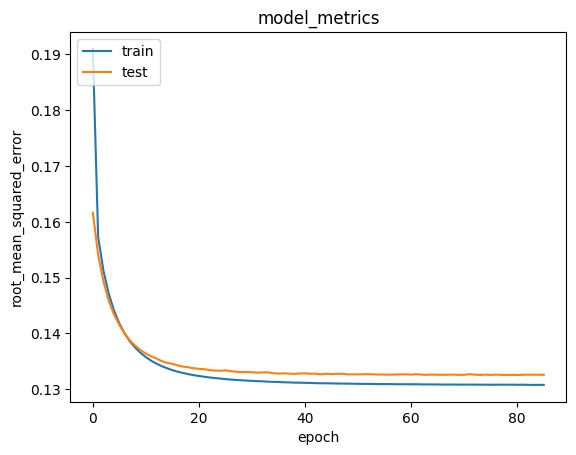

In [53]:
plt.plot(history.history['root_mean_squared_error'])
plt.plot(history.history['val_root_mean_squared_error'])
plt.title('model_metrics')
plt.ylabel('root_mean_squared_error')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

**Insight Kurva Metrik Model (RMSE)**


---



Grafik menunjukkan bagaimana RMSE model berubah seiring dengan bertambahnya epoch:

1.  **Penurunan Cepat di Awal**: Baik RMSE training (biru) maupun RMSE validasi (oranye) mengalami penurunan yang signifikan pada epoch-epoch awal. Ini menunjukkan model belajar dengan cepat dan efektif dari data.
2.  **Konvergensi**: Setelah sekitar 20-30 epoch, kedua kurva mulai melandai. Ini menandakan bahwa model mendekati titik konvergensi, di mana penambahan epoch hanya memberikan sedikit sekali perbaikan pada RMSE.
3.  **Performa Validasi Stabil**: RMSE validasi stabil di sekitar nilai ~0.132-0.133, sedikit di atas RMSE training. Ini adalah perilaku yang diharapkan.
4.  **Generalisasi yang Baik**: Jarak (gap) yang relatif kecil dan stabil antara kurva training dan validasi mengindikasikan bahwa model memiliki kemampuan generalisasi yang baik dan tidak mengalami *overfitting* yang signifikan. Ini juga didukung oleh fakta bahwa *early stopping* (yang digunakan sebelumnya) kemungkinan telah menghentikan pelatihan pada waktu yang tepat (sekitar epoch 80-an, dengan performa terbaik di sekitar epoch 79 seperti yang terlihat pada output teks sebelumnya).

Secara keseluruhan, plot ini memberikan konfirmasi visual bahwa model telah dilatih dengan baik, mencapai performa yang stabil pada data validasi, dan *callbacks* seperti *early stopping* bekerja secara efektif. Nilai RMSE validasi yang rendah (sekitar 0.1326) menunjukkan akurasi prediksi yang baik pada skala rating yang dinormalisasi.

## Mendapatkan Rekomendasi

In [43]:
# Menyiapkan dataframe
anime_df = anime_cleaned[['anime_id','name','genre','type','members','episodes', 'rating']]
anime_df.columns = ['id','anime_name','anime_genre','anime_type','anime_members', 'anime_episodes', 'anime_rating']
rating_df = rating_filtered.copy()

# Pemetaan kembali index ke user_id dan anime_id
index_to_anime = {idx: anime_id for anime_id, idx in anime_to_index.items()}

# Mengambil sample user
user_id = rating_df.user_id.sample(1).iloc[0]
anime_watched_by_user = rating_df[rating_df.user_id == user_id]


# Membuat data anime yang belum ditonton user
anime_not_watched = anime_df[~anime_df['id'].isin(anime_watched_by_user.anime_id.values)]['id']
anime_not_watched = list(
    set(anime_not_watched)
    .intersection(set(anime_to_index.keys()))
)

anime_not_watched = [[anime_to_index.get(x)] for x in anime_not_watched]
user_encoder = user_to_index.get(user_id)
user_anime_array = np.hstack(
    ([[user_encoder]] * len(anime_not_watched), anime_not_watched)
)


# Prediksi rating untuk semua anime yang belum ditonton user
ratings = model.predict(user_anime_array).flatten()

# Ambil indeks 10 anime dengan rating prediksi tertinggi
top_ratings_indices = ratings.argsort()[-10:][::-1]

# Ambil ID anime dari hasil prediksi terbaik
recommended_anime_ids = [
    index_to_anime.get(anime_not_watched[idx][0])
    for idx in top_ratings_indices
]

# Header rekomendasi
print(f"Daftar rekomendasi untuk: User {user_id}")
print("=" * 45, '\n')

# Menampilkan 5 anime dengan rating tertinggi yang pernah ditonton user
print("anime dengan rating paling tinggi dari user")
print("-" * 60)

top_anime_user_ids = (
    anime_watched_by_user
    .sort_values(by='rating', ascending=False)
    .head(5)
    .anime_id
    .values
)

# FIX: Change 'anime_id' to 'id' and use top_anime_user_ids instead of anime_id variable
top_anime_user_df = anime_df[anime_df['id'].isin(top_anime_user_ids)]

for row in top_anime_user_df.itertuples():
    print(f"{row.anime_name} : {row.anime_genre}")

print("\n" + "-" * 60)
print("Top 10 Rekomendasi anime untuk Anda")
print("-" * 60)

# Menampilkan daftar 10 anime rekomendasi
recommended_anime_df = anime_df[anime_df['id'].isin(recommended_anime_ids)]

for i, row in enumerate(recommended_anime_df.itertuples(), start=1):
    print(f"{i}. {row.anime_name}")
    print(f"    genre       : {row.anime_genre}")
    print(f"    type       : {row.anime_type}")
    # Consider using the predicted rating instead of anime_rating from the original dataset
    # print(f"    Predicted rating: {ratings[top_ratings_indices[i-1]]:.2f}")
    print(f"    rating     : {row.anime_rating}") # This is the original mean rating, not the prediction
    print(f"    members    : {row.anime_members}")
    print(f"    episodes   : {row.anime_episodes}")

print("=" * 45)

228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Daftar rekomendasi untuk: User 39397

anime dengan rating paling tinggi dari user
------------------------------------------------------------
Death Note : Mystery, Police, Psychological, Supernatural, Thriller
Durarara!! : Action, Mystery, Supernatural
Break Blade 2: Ketsubetsu no Michi : Action, Fantasy, Mecha, Military, Shounen
Black Cat : Adventure, Comedy, Sci-Fi, Shounen, Super Power
Uragiri wa Boku no Namae wo Shitteiru : Adventure, Drama, Fantasy, Shoujo, Shounen Ai

------------------------------------------------------------
Top 10 Rekomendasi anime untuk Anda
------------------------------------------------------------
1. Ashita no Nadja
    genre       : Adventure, Drama, Historical, Romance, Shoujo
    type       : TV
    rating     : 7.68
    members    : 13742
    episodes   : 50
2. Konjiki no Gash Bell!!
    genre       : Adventure, Comedy, Magic, Shounen, Supernatural
    type       : TV
    rating     : 7.66
    members    : 51

**Insight Proses Rekomendasi CF**


---



1.  **Persiapan & Pemilihan Pengguna**:
    * Data anime dan rating disiapkan. `anime_id` dipetakan ke indeks internal model.
    * Seorang pengguna (`User 39397` dalam contoh output Anda) dipilih secara acak.

2.  **Generasi Kandidat & Prediksi**:
    * Sistem mengidentifikasi anime yang **belum ditonton** oleh pengguna tersebut namun dikenal oleh model CF.
    * Model CF (`model.predict()`) kemudian digunakan untuk **memprediksi potensi rating** pengguna tersebut untuk semua anime yang belum ditonton ini. Output `226/226 ... 0s 2ms/step` menunjukkan proses prediksi sedang berjalan.

3.  **Seleksi Top Rekomendasi**:
    * Berdasarkan skor prediksi tertinggi, 10 anime teratas dipilih sebagai rekomendasi.

4.  **Tampilan Output**:
    * **Histori Pengguna**: Menampilkan 5 anime dengan rating tertinggi yang pernah diberikan oleh pengguna tersebut, lengkap dengan nama dan genrenya. Ini memberikan konteks tentang selera pengguna.
    * **Top 10 Rekomendasi**: Menampilkan 10 anime yang direkomendasikan. Untuk setiap rekomendasi, ditampilkan:
        * Nama Anime
        * Genre
        * Tipe
        * **Rating**: Penting untuk dicatat bahwa rating yang ditampilkan di sini adalah **rating rata-rata asli anime tersebut dari dataset (`row.anime_rating`)**, bukan skor prediksi yang spesifik dari model CF untuk pengguna tersebut. Model CF digunakan untuk *memilih dan mengurutkan* anime-anime ini, tetapi skor yang ditampilkan adalah skor global.
        * Jumlah Members
        * Jumlah Episode

**Poin Kunci**:
* Proses ini menunjukkan alur lengkap dari pemilihan pengguna, prediksi menggunakan model CF, hingga penyajian rekomendasi yang dipersonalisasi.
* Outputnya menggabungkan informasi histori pengguna dengan rekomendasi baru, yang merupakan praktik baik.
* Ada perbedaan antara **skor prediksi CF** (yang digunakan untuk membuat peringkat rekomendasi) dan **rating yang ditampilkan** untuk item yang direkomendasikan (yang dalam kasus ini adalah rating rata-rata global item tersebut). Jika Anda ingin menampilkan skor prediksi CF spesifik untuk pengguna tersebut, Anda perlu mengambilnya dari variabel `ratings` yang dihasilkan oleh `model.predict()`.
